# BÀI THỰC HÀNH 06: HUẤN LUYỆN VÀ SO SÁNH CÁC MÔ HÌNH HỌC MÁY
## Bước 1: Khai báo thư viện và đọc dữ liệu Train
- Đầu vào: 27 đặc trưng RIASEC (X) và 6 nhãn Q5 từ tập Train (3.963 mẫu).

In [1]:
from pathlib import Path
import sys,hashlib
import pandas as pd
import numpy as np
from IPython.display import display
assert sys.version_info[:2] == (3,14)
ROOT = next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'dataLabanAI.xlsx').is_file())
workbook_path = ROOT/'dataLabanAI.xlsx'
sha_before = hashlib.sha256(workbook_path.read_bytes()).hexdigest()
sha_notebook00 = 'c8a9445edba02a37cf862a3b1eabffba910eb7eeaf1d48b4c6f8ac19fea296c8'
assert sha_before == sha_notebook00, 'Workbook khác phiên bản Notebook 00; cần audit lại trước xử lý.'
excel = pd.ExcelFile(workbook_path)
assert excel.sheet_names == ['THONG_TIN','RIASEC_27','SO_THICH_6','CODEBOOK_33','KIEM_TRA']
raw_riasec = pd.read_excel(excel,sheet_name='RIASEC_27')
raw_q5 = pd.read_excel(excel,sheet_name='SO_THICH_6')
raw_codebook = pd.read_excel(excel,sheet_name='CODEBOOK_33')
# Bản sao gốc dùng đối chiếu, không thay đổi các DataFrame này.
original_riasec = raw_riasec.copy(deep=True)
original_q5 = raw_q5.copy(deep=True)
original_codebook = raw_codebook.copy(deep=True)
print('Python:',sys.version,'; Interpreter:',sys.executable)
print('SHA-256:',sha_before)
display(pd.DataFrame([{'Sheet':name,'Số dòng':len(frame),'Số cột':frame.shape[1]}
    for name,frame in [('RIASEC_27',raw_riasec),('SO_THICH_6',raw_q5),('CODEBOOK_33',raw_codebook)]]))


Python: 3.14.7 (tags/v3.14.7:823f032, Aug  5 2026, 10:51:32) [MSC v.1944 64 bit (AMD64)] ; Interpreter: C:\Users\DELL\AppData\Local\Programs\Python\Python314\python.exe
SHA-256: c8a9445edba02a37cf862a3b1eabffba910eb7eeaf1d48b4c6f8ac19fea296c8
         Sheet  Số dòng  Số cột
0    RIASEC_27     4910      28
1   SO_THICH_6     4910       7
2  CODEBOOK_33       33       5


In [2]:
question_columns = ['R1','I1','A1','R2','I2','A2','S1','S2','R3','A3','S3','E1','R4','S4','E2','R5','I3','A4','E3','I4','A5','E4','C1','E5','C2','C3','C4']
q5_columns = ['Q5_LikeRe','Q5_LikeIn','Q5_LikeAr','Q5_LikeSo','Q5_LikeEn','Q5_LikeCo']
survey_columns = question_columns+q5_columns
assert raw_riasec.shape == (4910,28) and raw_q5.shape == (4910,7)
assert list(raw_riasec.columns) == ['SOURCE_ROW']+question_columns
assert list(raw_q5.columns) == ['SOURCE_ROW']+q5_columns
assert raw_codebook.MA_COT.is_unique and raw_codebook.MA_COT.tolist() == survey_columns
assert raw_codebook.iloc[:27]['LOAI'].eq('RIASEC rút gọn').all()
assert raw_codebook.iloc[27:]['LOAI'].eq('Mức ưa thích nhóm nghề').all()
assert raw_codebook.iloc[:27]['THANG_DIEM_GOC'].nunique()==1
assert raw_codebook.iloc[27:]['THANG_DIEM_GOC'].nunique()==1
for frame in [raw_riasec,raw_q5]:
    assert frame.SOURCE_ROW.notna().all() and frame.SOURCE_ROW.is_unique
    assert pd.api.types.is_integer_dtype(frame.SOURCE_ROW)
assert set(raw_riasec.SOURCE_ROW) == set(raw_q5.SOURCE_ROW)
merged = raw_riasec.merge(raw_q5,on='SOURCE_ROW',how='outer',validate='one_to_one',indicator=True,sort=False)
display(merged['_merge'].value_counts().rename('Số dòng sau ghép').to_frame())
assert len(merged) == len(raw_riasec) == len(raw_q5) == 4910
assert merged['_merge'].eq('both').all()
merged = merged.drop(columns='_merge').set_index('SOURCE_ROW').loc[raw_riasec.SOURCE_ROW].reset_index()
assert merged.SOURCE_ROW.equals(raw_riasec.SOURCE_ROW)
assert merged[question_columns].equals(raw_riasec[question_columns])
assert merged[q5_columns].equals(raw_q5.set_index('SOURCE_ROW').loc[raw_riasec.SOURCE_ROW,q5_columns].reset_index(drop=True))
df_original = merged.copy(deep=True)
raw_survey = df_original[survey_columns].copy()
print('PASS: ghép một-một, không mất/thêm dòng, giữ thứ tự nguồn và 33 biến.')


PASS: ghép một-một, không mất/thêm dòng, giữ thứ tự nguồn và 33 biến.


            Số dòng sau ghép
_merge                      
both                    4910
left_only                  0
right_only                 0

In [3]:
type_rows = []
for col in survey_columns:
    values = raw_survey[col]
    numeric = pd.to_numeric(values,errors='coerce')
    is_numeric_cell = values.map(lambda value:isinstance(value,(int,float,np.integer,np.floating)) and not isinstance(value,(bool,np.bool_)))
    valid = is_numeric_cell & numeric.isin([1,2,3,4,5])
    type_rows.append({'Cột':col,'dtype gốc':str(values.dtype),'Thiếu':int(values.isna().sum()),
        'Sai kiểu hoặc ngoài miền':int((values.notna() & ~valid).sum())})
type_check = pd.DataFrame(type_rows).set_index('Cột')
display(type_check)
if type_check['Thiếu'].sum() or type_check['Sai kiểu hoặc ngoài miền'].sum():
    raise RuntimeError('Có giá trị sai/thiếu; dừng để quyết định xử lý, không tự sửa.')
survey_int = raw_survey.astype('int64')
assert np.array_equal(survey_int.to_numpy(),raw_survey.to_numpy())
assert survey_int.isin(range(1,6)).all().all()
assert all(pd.api.types.is_integer_dtype(dtype) for dtype in survey_int.dtypes)
answers27 = survey_int[question_columns].copy()
preferences6 = survey_int[q5_columns].copy()
print('PASS: đủ 33 biến, không thiếu/sai kiểu/ngoài miền; chuyển int64 không đổi giá trị.')


PASS: đủ 33 biến, không thiếu/sai kiểu/ngoài miền; chuyển int64 không đổi giá trị.


          dtype gốc  Thiếu  Sai kiểu hoặc ngoài miền
Cột                                                 
R1            int64      0                         0
I1            int64      0                         0
A1            int64      0                         0
R2            int64      0                         0
I2            int64      0                         0
A2            int64      0                         0
S1            int64      0                         0
S2            int64      0                         0
R3            int64      0                         0
A3            int64      0                         0
S3            int64      0                         0
E1            int64      0                         0
R4            int64      0                         0
S4            int64      0                         0
E2            int64      0                         0
R5            int64      0                         0
I3            int64      0                    

In [4]:
from sklearn.model_selection import GroupShuffleSplit
import sklearn
X = answers27.copy()
y = preferences6.copy()
groups = pd.Series(pd.factorize(pd.MultiIndex.from_frame(X),sort=False)[0],index=X.index,name='group_X27')
splitter = GroupShuffleSplit(n_splits=1,test_size=0.2,random_state=42)
train_pos,test_pos = next(splitter.split(X,groups=groups))
X_train,X_test = X.iloc[train_pos].copy(),X.iloc[test_pos].copy()
y_train,y_test = y.iloc[train_pos].copy(),y.iloc[test_pos].copy()
groups_train,groups_test = groups.iloc[train_pos].copy(),groups.iloc[test_pos].copy()
assert X_train.shape==(3963,27) and X_test.shape==(947,27)
assert y_train.shape==(3963,6) and y_test.shape==(947,6)
assert groups_train.nunique()==3568 and groups_test.nunique()==892
assert X.index.is_unique and X_train.index.intersection(X_test.index).empty
assert len(X_train)+len(X_test)==4910
assert set(X_train.index)|set(X_test.index)==set(X.index)
assert set(groups_train).isdisjoint(groups_test)
assert set(X_train.itertuples(index=False,name=None)).isdisjoint(X_test.itertuples(index=False,name=None))
assert list(X_train.columns)==list(X_test.columns)==question_columns
assert list(y_train.columns)==list(y_test.columns)==q5_columns
assert y_train.index.equals(X_train.index) and y_test.index.equals(X_test.index)
assert y_train.equals(y.loc[X_train.index]) and y_test.equals(y.loc[X_test.index])
train_index_sha256=hashlib.sha256(np.asarray(X_train.index,dtype='<i8').tobytes()).hexdigest()
test_index_sha256=hashlib.sha256(np.asarray(X_test.index,dtype='<i8').tobytes()).hexdigest()
assert train_index_sha256=='471fecbbc5d665e949eae03bcdebedc996044f30136a56d8b1d698ad3d7e2d4d'
assert test_index_sha256=='92594157a2b76a9d59f375dd14bf6617cd5b58232f368b86688e17c011d8392b'
print('PASS: đúng index Notebook 02; Train 3963×27, 3568 group; Test 947×27, 892 group; y có 6 cột.')
print('SHA index Train/Test:',train_index_sha256,test_index_sha256)
print('pandas/numpy/sklearn:',pd.__version__,np.__version__,sklearn.__version__)
# Giữ codebook và đường dẫn/hash; bỏ các DataFrame có phản hồi Test/toàn tập.
SOURCE_ROW_train=df_original.loc[X_train.index,'SOURCE_ROW'].copy()
del X_test,y_test,groups_test,X,y,groups,train_pos,test_pos
# Các bản sao toàn tập từ bước đọc/làm sạch cũng không dùng cho huấn luyện chỉ trên Train.
del raw_riasec,raw_q5,original_riasec,original_q5,merged,df_original,raw_survey,survey_int,answers27,preferences6

# Bỏ cả alias còn lại của các vòng kiểm tra kiểu/khóa.
del frame,values,numeric,is_numeric_cell,valid


PASS: đúng index Notebook 02; Train 3963×27, 3568 group; Test 947×27, 892 group; y có 6 cột.
SHA index Train/Test: 471fecbbc5d665e949eae03bcdebedc996044f30136a56d8b1d698ad3d7e2d4d 92594157a2b76a9d59f375dd14bf6617cd5b58232f368b86688e17c011d8392b
pandas/numpy/sklearn: 3.0.6 2.5.3 1.9.1


## Bước 2: Thiết lập Group 5-Fold Cross-Validation
- Chống rò rỉ dữ liệu: `GroupKFold` với k=5 chia theo 3.568 nhóm định danh vector X27 trên Train.

In [5]:
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.preprocessing import StandardScaler,MinMaxScaler
from sklearn.feature_selection import SelectKBest,f_classif
from sklearn.dummy import DummyClassifier,DummyRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (mean_absolute_error,accuracy_score,f1_score,balanced_accuracy_score,
                             classification_report,confusion_matrix)
from sklearn.exceptions import ConvergenceWarning
import warnings
X_snapshot=X_train.copy(deep=True)
y_snapshot=y_train.copy(deep=True)
cv=GroupKFold(n_splits=5)
folds=list(cv.split(X_train,groups=groups_train))
fold_rows=[]
support_rows=[]
seen=[]
train_sizes=groups_train.value_counts()
largest_group=train_sizes.idxmax()
assert train_sizes.max()==188
for fold,(tr,va) in enumerate(folds,1):
    assert len(tr)+len(va)==3963 and set(tr).isdisjoint(va)
    assert X_train.iloc[tr].index.intersection(X_train.iloc[va].index).empty
    assert set(SOURCE_ROW_train.iloc[tr]).isdisjoint(SOURCE_ROW_train.iloc[va])
    assert set(groups_train.iloc[tr]).isdisjoint(groups_train.iloc[va])
    assert set(X_train.iloc[tr].itertuples(index=False,name=None)).isdisjoint(X_train.iloc[va].itertuples(index=False,name=None))
    seen.extend(va)
    fold_rows.append({'Fold':fold,'Training n':len(tr),'Validation n':len(va),
        'Training groups':groups_train.iloc[tr].nunique(),'Validation groups':groups_train.iloc[va].nunique(),
        'Nhóm 188 trong training':int(groups_train.iloc[tr].eq(largest_group).sum()),
        'Nhóm 188 trong validation':int(groups_train.iloc[va].eq(largest_group).sum())})
    for target in q5_columns:
        a=y_train[target].iloc[tr].value_counts().reindex(range(1,6),fill_value=0)
        v=y_train[target].iloc[va].value_counts().reindex(range(1,6),fill_value=0)
        support_rows.append({'Q5':target,'Fold':fold,
            **{f'Train mức {level}':int(a[level]) for level in range(1,6)},
            **{f'Valid mức {level}':int(v[level]) for level in range(1,6)},
            'Train thiếu mức':','.join(str(level) for level in a.index[a.eq(0)]),
            'Valid thiếu mức':','.join(str(level) for level in v.index[v.eq(0)])})
        if a.gt(0).sum()<2:
            raise RuntimeError('Training fold có dưới hai mức; dừng xem xét, không đổi seed/nhãn.')
assert sorted(seen)==list(range(3963))
fold_table=pd.DataFrame(fold_rows)
fold_support=pd.DataFrame(support_rows)
display(fold_table)
display(fold_support)
missing_support=fold_support[(fold_support['Train thiếu mức']!='')|(fold_support['Valid thiếu mức']!='')]
print('Số dòng Q5/fold thiếu mức:',len(missing_support))
if not missing_support.empty:display(missing_support)
print('Vector X27 trùng khác Q5 trong Train:',int(y_train.groupby(groups_train).nunique().gt(1).any(axis=1).sum()),'nhóm')


Số dòng Q5/fold thiếu mức: 0
Vector X27 trùng khác Q5 trong Train: 43 nhóm


   Fold  Training n  Validation n  Training groups  Validation groups  Nhóm 188 trong training  Nhóm 188 trong validation
0     1        3170           793             2962                606                        0                        188
1     2        3170           793             2834                734                      188                          0
2     3        3170           793             2827                741                      188                          0
3     4        3171           792             2825                743                      188                          0
4     5        3171           792             2824                744                      188                          0

           Q5  Fold  Train mức 1  Train mức 2  Train mức 3  Train mức 4  Train mức 5  Valid mức 1  Valid mức 2  Valid mức 3  Valid mức 4  Valid mức 5 Train thiếu mức Valid thiếu mức
0   Q5_LikeRe     1          915          769          843          338          305          177          194          260           89           73                                
1   Q5_LikeIn     1          727          690          811          512          430          146          157          268          125           97                                
2   Q5_LikeAr     1          616          588          801          547          618          131          146          267          130          119                                
3   Q5_LikeSo     1          606          670          917          530          447          129          159          262          146           97                                
4   Q5_LikeEn     1          632          639          862          584          453      

## Bước 3: Định nghĩa cấu hình mô hình phân loại thứ bậc (5 mức)
- Mô hình thử nghiệm: DummyMost, Logistic Regression (Raw, Std, MinMax), Random Forest.

In [6]:
configs=[]
for priority,(identifier,scaler,k,predictor,kind) in enumerate([
    ('Median','passthrough',27,DummyRegressor(strategy='median'),'median'),
    ('DummyMost','passthrough',27,DummyClassifier(strategy='most_frequent'),'classifier'),
    ('LR_Raw27','passthrough',27,LogisticRegression(C=1,solver='lbfgs',max_iter=10000,tol=1e-4,random_state=42),'classifier'),
    ('LR_Std27',StandardScaler(),27,LogisticRegression(C=1,solver='lbfgs',max_iter=10000,tol=1e-4,random_state=42),'classifier'),
    ('LR_MinMax27',MinMaxScaler(feature_range=(0,1)),27,LogisticRegression(C=1,solver='lbfgs',max_iter=10000,tol=1e-4,random_state=42),'classifier'),
    ('LR_Std18',StandardScaler(),18,LogisticRegression(C=1,solver='lbfgs',max_iter=10000,tol=1e-4,random_state=42),'classifier'),
    ('LR_Std10',StandardScaler(),10,LogisticRegression(C=1,solver='lbfgs',max_iter=10000,tol=1e-4,random_state=42),'classifier'),
    ('RF_Raw27','passthrough',27,RandomForestClassifier(n_estimators=100,max_depth=10,min_samples_leaf=5,max_features='sqrt',random_state=42,n_jobs=1),'classifier')]):
    configs.append({'ID':identifier,'k':k,'kind':kind,'Priority':priority,
        'Scaler':type(scaler).__name__ if not isinstance(scaler,str) else 'passthrough',
        'Selector':'SelectKBest(f_classif)' if k<27 else 'passthrough',
        'Pipeline':Pipeline([('scaler',scaler),('selector',SelectKBest(f_classif,k=k) if k<27 else 'passthrough'),('predictor',predictor)])})
config_ids=[c['ID'] for c in configs]
assert len(configs)==8
display(pd.DataFrame([{key:value for key,value in c.items() if key!='Pipeline'} for c in configs]))
for c in configs:print(c['ID'],c['Pipeline'])


Median Pipeline(steps=[('scaler', 'passthrough'), ('selector', 'passthrough'),
                ('predictor', DummyRegressor(strategy='median'))])
DummyMost Pipeline(steps=[('scaler', 'passthrough'), ('selector', 'passthrough'),
                ('predictor', DummyClassifier(strategy='most_frequent'))])
LR_Raw27 Pipeline(steps=[('scaler', 'passthrough'), ('selector', 'passthrough'),
                ('predictor',
                 LogisticRegression(C=1, max_iter=10000, random_state=42))])
LR_Std27 Pipeline(steps=[('scaler', StandardScaler()), ('selector', 'passthrough'),
                ('predictor',
                 LogisticRegression(C=1, max_iter=10000, random_state=42))])
LR_MinMax27 Pipeline(steps=[('scaler', MinMaxScaler()), ('selector', 'passthrough'),
                ('predictor',
                 LogisticRegression(C=1, max_iter=10000, random_state=42))])
LR_Std18 Pipeline(steps=[('scaler', StandardScaler()), ('selector', SelectKBest(k=18)),
                ('predictor',
        

            ID   k        kind  Priority          Scaler                Selector
0       Median  27      median         0     passthrough             passthrough
1    DummyMost  27  classifier         1     passthrough             passthrough
2     LR_Raw27  27  classifier         2     passthrough             passthrough
3     LR_Std27  27  classifier         3  StandardScaler             passthrough
4  LR_MinMax27  27  classifier         4    MinMaxScaler             passthrough
5     LR_Std18  18  classifier         5  StandardScaler  SelectKBest(f_classif)
6     LR_Std10  10  classifier         6  StandardScaler  SelectKBest(f_classif)
7     RF_Raw27  27  classifier         7     passthrough             passthrough

## Bước 4: Huấn luyện và thu thập dự đoán Out-Of-Fold (OOF)
- Thực thi: Group 5-Fold CV trên 6 biến mục tiêu Q5.

In [7]:
records=[]
warning_rows=[]
oof_predictions={}
cv_fit_count=0
for target in q5_columns:
    print('Đang huấn luyện mục tiêu:',target,flush=True)
    for config in configs:
        print('  Cấu hình:',config['ID'],flush=True)
        oof=np.full(len(X_train),np.nan)
        for fold,(tr,va) in enumerate(folds,1):
            model=clone(config['Pipeline'])
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter('always')
                model.fit(X_train.iloc[tr],y_train[target].iloc[tr])
                cv_fit_count+=1
                raw_prediction=np.asarray(model.predict(X_train.iloc[va]))
            if config['kind']=='median':
                prediction=np.floor(raw_prediction).astype('int64')
            else:
                assert np.equal(raw_prediction,np.rint(raw_prediction)).all()
                prediction=raw_prediction.astype('int64')
            assert model.named_steps['predictor'].n_features_in_==config['k']
            assert prediction.shape==(len(va),) and np.isin(prediction,[1,2,3,4,5]).all()
            convergence=any(issubclass(w.category,ConvergenceWarning) for w in caught)
            for w in caught:warning_rows.append({'Stage':'CV','Q5':target,'ID':config['ID'],'Fold':fold,'Category':w.category.__name__,'Message':str(w.message)})
            truth=y_train[target].iloc[va].to_numpy()
            records.append({'Q5':target,'ID':config['ID'],'Fold':fold,'Validation n':len(va),
                'MAE':mean_absolute_error(truth,prediction),
                'Accuracy':accuracy_score(truth,prediction),
                'Macro-F1':f1_score(truth,prediction,labels=[1,2,3,4,5],average='macro',zero_division=0),
                'Balanced Accuracy':balanced_accuracy_score(truth,prediction),
                'ConvergenceWarning':convergence})
            oof[va]=prediction
            del model
        assert np.isfinite(oof).all()
        oof_predictions[(target,config['ID'])]=oof.astype('int64')
cv_results=pd.DataFrame(records)
assert cv_fit_count==240 and len(cv_results)==240
assert cv_results.groupby(['Q5','ID']).size().eq(5).all()
print('Số lượt fit CV:',cv_fit_count,'; số cảnh báo CV:',len(warning_rows))
if warning_rows:display(pd.DataFrame(warning_rows))
# Đủ 240 hàng: mọi chỉ số cho từng Q5/config/fold.
display(cv_results)


Đang huấn luyện mục tiêu: Q5_LikeRe
  Cấu hình: Median
  Cấu hình: DummyMost
  Cấu hình: LR_Raw27
  Cấu hình: LR_Std27
  Cấu hình: LR_MinMax27
  Cấu hình: LR_Std18
  Cấu hình: LR_Std10
  Cấu hình: RF_Raw27
Đang huấn luyện mục tiêu: Q5_LikeIn
  Cấu hình: Median
  Cấu hình: DummyMost
  Cấu hình: LR_Raw27
  Cấu hình: LR_Std27
  Cấu hình: LR_MinMax27
  Cấu hình: LR_Std18
  Cấu hình: LR_Std10
  Cấu hình: RF_Raw27
Đang huấn luyện mục tiêu: Q5_LikeAr
  Cấu hình: Median
  Cấu hình: DummyMost
  Cấu hình: LR_Raw27
  Cấu hình: LR_Std27
  Cấu hình: LR_MinMax27
  Cấu hình: LR_Std18
  Cấu hình: LR_Std10
  Cấu hình: RF_Raw27
Đang huấn luyện mục tiêu: Q5_LikeSo
  Cấu hình: Median
  Cấu hình: DummyMost
  Cấu hình: LR_Raw27
  Cấu hình: LR_Std27
  Cấu hình: LR_MinMax27
  Cấu hình: LR_Std18
  Cấu hình: LR_Std10
  Cấu hình: RF_Raw27
Đang huấn luyện mục tiêu: Q5_LikeEn
  Cấu hình: Median
  Cấu hình: DummyMost
  Cấu hình: LR_Raw27
  Cấu hình: LR_Std27
  Cấu hình: LR_MinMax27
  Cấu hình: LR_Std18
  Cấu hình: 

            Q5           ID  Fold  Validation n       MAE  Accuracy  Macro-F1  Balanced Accuracy  ConvergenceWarning
0    Q5_LikeRe       Median     1           793  1.051702  0.244641  0.078622           0.200000               False
1    Q5_LikeRe       Median     2           793  1.121059  0.226986  0.073998           0.200000               False
2    Q5_LikeRe       Median     3           793  1.045397  0.244641  0.078622           0.200000               False
3    Q5_LikeRe       Median     4           792  1.039141  0.237374  0.076735           0.200000               False
4    Q5_LikeRe       Median     5           792  1.020202  0.261364  0.082883           0.200000               False
5    Q5_LikeRe    DummyMost     1           793  1.605296  0.223203  0.072990           0.200000               False
6    Q5_LikeRe    DummyMost     2           793  1.112232  0.276166  0.086561           0.200000               False
7    Q5_LikeRe    DummyMost     3           793  1.157629  0.248

## Bước 5: Bảng tổng hợp kết quả Cross-Validation (5 mức)
- Chỉ số: Accuracy, Balanced Accuracy, Macro-F1, MAE trung bình qua 5 folds.

In [8]:
metrics=['MAE','Accuracy','Macro-F1','Balanced Accuracy']
summary_rows=[]
for target in q5_columns:
    for config in configs:
        rows=cv_results[(cv_results['Q5']==target)&(cv_results['ID']==config['ID'])]
        item={'Q5':target,'ID':config['ID'],'k':config['k'],'Scaler':config['Scaler'],
            'Selector':config['Selector'],'Priority':config['Priority'],'Folds':len(rows),
            'Eligible':len(rows)==5 and not rows['ConvergenceWarning'].any()}
        for metric in metrics:
            item[metric+' mean']=rows[metric].mean()
            item[metric+' SD']=rows[metric].std(ddof=1)
        summary_rows.append(item)
summary=pd.DataFrame(summary_rows)
assert len(summary)==48
display(summary.sort_values(['Q5','MAE mean']).round(6))
print('Baseline riêng từng Q5:')
baseline_summary=summary[summary['ID'].isin(['Median','DummyMost'])]
display(baseline_summary[['Q5','ID','MAE mean','MAE SD','Accuracy mean','Accuracy SD']].round(6))


Baseline riêng từng Q5:


           Q5           ID   k          Scaler                Selector  Priority  Folds  Eligible  MAE mean    MAE SD  Accuracy mean  Accuracy SD  Macro-F1 mean  Macro-F1 SD  Balanced Accuracy mean  Balanced Accuracy SD
23  Q5_LikeAr     RF_Raw27  27     passthrough             passthrough         7      5      True  0.956611  0.061244       0.402217     0.022258       0.351111     0.011590                0.374837              0.010151
18  Q5_LikeAr     LR_Raw27  27     passthrough             passthrough         2      5      True  0.983854  0.056583       0.388845     0.022310       0.328624     0.017184                0.362629              0.018684
19  Q5_LikeAr     LR_Std27  27  StandardScaler             passthrough         3      5      True  0.983854  0.054514       0.388340     0.021950       0.328289     0.016900                0.362215              0.018715
20  Q5_LikeAr  LR_MinMax27  27    MinMaxScaler             passthrough         4      5      True  0.984864  0.053534   

           Q5         ID  MAE mean    MAE SD  Accuracy mean  Accuracy SD
0   Q5_LikeRe     Median  1.055500  0.038497       0.243001     0.012557
1   Q5_LikeRe  DummyMost  1.216193  0.218698       0.257387     0.022545
8   Q5_LikeIn     Median  1.081006  0.066735       0.272263     0.037563
9   Q5_LikeIn  DummyMost  1.081006  0.066735       0.272263     0.037563
16  Q5_LikeAr     Median  1.104978  0.073096       0.269491     0.039855
17  Q5_LikeAr  DummyMost  1.104978  0.073096       0.269491     0.039855
24  Q5_LikeSo     Median  1.025237  0.042638       0.297501     0.022133
25  Q5_LikeSo  DummyMost  1.025237  0.042638       0.297501     0.022133
32  Q5_LikeEn     Median  1.041394  0.065427       0.286140     0.033385
33  Q5_LikeEn  DummyMost  1.041394  0.065427       0.286140     0.033385
40  Q5_LikeCo     Median  1.063099  0.047599       0.274783     0.025270
41  Q5_LikeCo  DummyMost  1.063099  0.047599       0.274783     0.025270

## Bước 6: Lựa chọn cấu hình tốt nhất cho từng biến Q5 (5 mức)
- Đầu ra: Cấu hình đạt hiệu năng phân loại cao nhất trên bài toán 5 mức.

In [9]:
chosen_ids={}
choice_trace=[]
best_rows=[]
for target in q5_columns:
    available=summary[(summary['Q5']==target)&summary['Eligible']].copy()
    if available.empty:raise RuntimeError('Không có cấu hình đủ điều kiện cho '+target)
    absolute_best=available.sort_values(['MAE mean','ID']).iloc[0]
    near=available[available['MAE mean']<=available['MAE mean'].min()+.01]
    mae_candidates=near['ID'].tolist()
    near=near[near['Macro-F1 mean']>=near['Macro-F1 mean'].max()-.005]
    f1_candidates=near['ID'].tolist()
    near=near[near['MAE SD']<=near['MAE SD'].min()+.005]
    stable_candidates=near['ID'].tolist()
    chosen=near.sort_values(['Priority','ID']).iloc[0]
    chosen_ids[target]=chosen['ID']
    choice_trace.append({'Q5':target,'MAE thấp nhất tuyệt đối':absolute_best['ID'],
        'Gần theo MAE':', '.join(mae_candidates),'Sau Macro-F1':', '.join(f1_candidates),
        'Sau độ ổn định':', '.join(stable_candidates),'Chốt':chosen['ID']})
    median=available[available['ID']=='Median'].iloc[0]
    dummy=available[available['ID']=='DummyMost'].iloc[0]
    item={'Q5':target,'Model tốt nhất':chosen['ID'],'Số đặc trưng':int(chosen['k'])}
    for metric in metrics:item['CV '+metric+' mean ± SD']=f"{chosen[metric+' mean']:.4f} ± {chosen[metric+' SD']:.4f}"
    item['Baseline Median MAE']=median['MAE mean']
    item['Baseline Median Accuracy']=median['Accuracy mean']
    item['DummyMost MAE']=dummy['MAE mean']
    item['DummyMost Accuracy']=dummy['Accuracy mean']
    item['Giảm MAE so Median']=median['MAE mean']-chosen['MAE mean']
    best_rows.append(item)
best_table=pd.DataFrame(best_rows)
display(pd.DataFrame(choice_trace))
display(best_table)
print('Cấu hình đã chốt (không đổi sau khi xem Test):',chosen_ids)
print('Đối chiếu scaler/selector/RF theo MAE, cùng C=1 cho LR:')
display(summary.pivot(index='Q5',columns='ID',values='MAE mean').round(6))
print('Đối chiếu Accuracy:')
display(summary.pivot(index='Q5',columns='ID',values='Accuracy mean').round(6))


Cấu hình đã chốt (không đổi sau khi xem Test): {'Q5_LikeRe': 'RF_Raw27', 'Q5_LikeIn': 'RF_Raw27', 'Q5_LikeAr': 'RF_Raw27', 'Q5_LikeSo': 'RF_Raw27', 'Q5_LikeEn': 'RF_Raw27', 'Q5_LikeCo': 'RF_Raw27'}
Đối chiếu scaler/selector/RF theo MAE, cùng C=1 cho LR:
Đối chiếu Accuracy:


          Q5 MAE thấp nhất tuyệt đối Gần theo MAE Sau Macro-F1 Sau độ ổn định      Chốt
0  Q5_LikeRe                RF_Raw27     RF_Raw27     RF_Raw27       RF_Raw27  RF_Raw27
1  Q5_LikeIn                RF_Raw27     RF_Raw27     RF_Raw27       RF_Raw27  RF_Raw27
2  Q5_LikeAr                RF_Raw27     RF_Raw27     RF_Raw27       RF_Raw27  RF_Raw27
3  Q5_LikeSo                RF_Raw27     RF_Raw27     RF_Raw27       RF_Raw27  RF_Raw27
4  Q5_LikeEn                RF_Raw27     RF_Raw27     RF_Raw27       RF_Raw27  RF_Raw27
5  Q5_LikeCo                RF_Raw27     RF_Raw27     RF_Raw27       RF_Raw27  RF_Raw27

          Q5 Model tốt nhất  Số đặc trưng CV MAE mean ± SD CV Accuracy mean ± SD CV Macro-F1 mean ± SD CV Balanced Accuracy mean ± SD  Baseline Median MAE  Baseline Median Accuracy  DummyMost MAE  DummyMost Accuracy  Giảm MAE so Median
0  Q5_LikeRe       RF_Raw27            27  0.8524 ± 0.0370       0.4386 ± 0.0179       0.3550 ± 0.0141                0.3661 ± 0.0171             1.055500                  0.243001       1.216193            0.257387            0.203127
1  Q5_LikeIn       RF_Raw27            27  0.8978 ± 0.0468       0.4106 ± 0.0161       0.3676 ± 0.0146                0.3784 ± 0.0160             1.081006                  0.272263       1.081006            0.272263            0.183205
2  Q5_LikeAr       RF_Raw27            27  0.9566 ± 0.0612       0.4022 ± 0.0223       0.3511 ± 0.0116                0.3748 ± 0.0102             1.104978                  0.269491       1.104978            0.269491            0.148367
3  Q5_LikeSo       RF_Raw27            27  0.9498 ± 0.04

ID         DummyMost  LR_MinMax27  LR_Raw27  LR_Std10  LR_Std18  LR_Std27    Median  RF_Raw27
Q5                                                                                           
Q5_LikeAr   1.104978     0.984864  0.983854  1.006568  1.003033  0.983854  1.104978  0.956611
Q5_LikeCo   1.063099     0.941194  0.940691  0.929839  0.931865  0.940691  1.063099  0.898546
Q5_LikeEn   1.041394     0.982079  0.985866  0.965179  0.967691  0.984604  1.041394  0.922270
Q5_LikeIn   1.081006     0.935646  0.936906  0.944220  0.934382  0.936653  1.081006  0.897800
Q5_LikeRe   1.216193     0.896280  0.896029  0.889714  0.900068  0.895525  1.055500  0.852373
Q5_LikeSo   1.025237     0.974008  0.975015  0.982077  0.985355  0.974511  1.025237  0.949777

ID         DummyMost  LR_MinMax27  LR_Raw27  LR_Std10  LR_Std18  LR_Std27    Median  RF_Raw27
Q5                                                                                           
Q5_LikeAr   0.269491     0.387836  0.388845  0.389093  0.388087  0.388340  0.269491  0.402217
Q5_LikeCo   0.274783     0.379258  0.380267  0.383801  0.385059  0.380267  0.274783  0.401464
Q5_LikeEn   0.286140     0.360082  0.358062  0.365631  0.366139  0.359324  0.286140  0.400209
Q5_LikeIn   0.272263     0.382541  0.383551  0.379261  0.387085  0.383299  0.272263  0.410550
Q5_LikeRe   0.257387     0.405752  0.406004  0.418374  0.408777  0.405751  0.243001  0.438560
Q5_LikeSo   0.297501     0.369415  0.368152  0.365634  0.365381  0.368404  0.297501  0.378755

## Bước 7: Đánh giá hiện tượng quá khớp (Overfitting)
- Đo lường: Độ chênh lệch Accuracy giữa tập Train và Validation.

In [10]:
full_train_models={}
train_cv_rows=[]
selected_metadata=[]
full_train_fit_count=0
for target in q5_columns:
    config=next(c for c in configs if c['ID']==chosen_ids[target])
    model=clone(config['Pipeline'])
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        model.fit(X_train,y_train[target])
        full_train_fit_count+=1
        raw_prediction=np.asarray(model.predict(X_train))
    prediction=np.floor(raw_prediction).astype('int64') if config['kind']=='median' else raw_prediction.astype('int64')
    assert np.isin(prediction,[1,2,3,4,5]).all()
    for w in caught:warning_rows.append({'Stage':'Full Train','Q5':target,'ID':config['ID'],'Fold':None,'Category':w.category.__name__,'Message':str(w.message)})
    row=summary[(summary['Q5']==target)&(summary['ID']==config['ID'])].iloc[0]
    train_mae=mean_absolute_error(y_train[target],prediction)
    train_acc=accuracy_score(y_train[target],prediction)
    train_cv_rows.append({'Q5':target,'ID':config['ID'],'Train MAE':train_mae,'CV MAE':row['MAE mean'],
        'CV MAE - Train MAE':row['MAE mean']-train_mae,
        'Train Accuracy':train_acc,'CV Accuracy':row['Accuracy mean'],
        'Train - CV Accuracy (điểm %)':(train_acc-row['Accuracy mean'])*100})
    metadata={'Q5':target,'ID':config['ID'],'k':config['k'],'Scaler':config['Scaler'],
        'Selector':config['Selector'],'Predictor class':type(model.named_steps['predictor']).__name__,
        'Predictor params':model.named_steps['predictor'].get_params(),
        'Scaler params':model.named_steps['scaler'].get_params() if config['Scaler']!='passthrough' else 'passthrough',
        'Selector params':{'score_func':'f_classif','k':config['k']} if config['k']<27 else 'passthrough',
        'Output rule':'floor median, chọn mức thấp hơn khi .5' if config['kind']=='median' else 'classifier.predict mức nguyên 1–5'}
    selected_metadata.append(metadata)
    full_train_models[target]=model
    print('CẤU HÌNH CHỐT:',metadata)
assert full_train_fit_count==6
train_cv_table=pd.DataFrame(train_cv_rows)
display(train_cv_table.round(6))
print('Tổng cảnh báo CV/full Train:',len(warning_rows))
if warning_rows:display(pd.DataFrame(warning_rows))


CẤU HÌNH CHỐT: {'Q5': 'Q5_LikeRe', 'ID': 'RF_Raw27', 'k': 27, 'Scaler': 'passthrough', 'Selector': 'passthrough', 'Predictor class': 'RandomForestClassifier', 'Predictor params': {'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': 10, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 5, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 100, 'n_jobs': 1, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}, 'Scaler params': 'passthrough', 'Selector params': 'passthrough', 'Output rule': 'classifier.predict mức nguyên 1–5'}
CẤU HÌNH CHỐT: {'Q5': 'Q5_LikeIn', 'ID': 'RF_Raw27', 'k': 27, 'Scaler': 'passthrough', 'Selector': 'passthrough', 'Predictor class': 'RandomForestClassifier', 'Predictor params': {'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': 10, 'max_features': 

          Q5        ID  Train MAE    CV MAE  CV MAE - Train MAE  Train Accuracy  CV Accuracy  Train - CV Accuracy (điểm %)
0  Q5_LikeRe  RF_Raw27   0.582892  0.852373            0.269481        0.657330     0.438560                     21.877069
1  Q5_LikeIn  RF_Raw27   0.562705  0.897800            0.335095        0.665153     0.410550                     25.460233
2  Q5_LikeAr  RF_Raw27   0.584153  0.956611            0.372457        0.659601     0.402217                     25.738431
3  Q5_LikeSo  RF_Raw27   0.586929  0.949777            0.362848        0.648751     0.378755                     26.999555
4  Q5_LikeEn  RF_Raw27   0.583649  0.922270            0.338621        0.652284     0.400209                     25.207504
5  Q5_LikeCo  RF_Raw27   0.572041  0.898546            0.326505        0.648246     0.401464                     24.678271

## Bước 8: Ma trận nhầm lẫn Out-Of-Fold và sai số lệch 1 mức
- Phân tích: Tỷ lệ dự đoán đúng và sai số lân cận trên thang đo 5 mức.

In [11]:
per_level_rows=[]
error_rows=[]
large_group_rows=[]
large_mask=groups_train.eq(largest_group).to_numpy()
assert large_mask.sum()==188
for target in q5_columns:
    prediction=oof_predictions[(target,chosen_ids[target])]
    truth=y_train[target].to_numpy()
    report=classification_report(truth,prediction,labels=[1,2,3,4,5],output_dict=True,zero_division=0)
    for level in range(1,6):
        r=report[str(level)]
        mask=truth==level
        per_level_rows.append({'Q5':target,'Mức thật':level,'Support':int(r['support']),
            'Precision':r['precision'],'Recall':r['recall'],'F1':r['f1-score'],
            'MAE theo mức thật':mean_absolute_error(truth[mask],prediction[mask])})
    matrix=confusion_matrix(truth,prediction,labels=[1,2,3,4,5])
    pairs=[(i+1,j+1,int(matrix[i,j])) for i in range(5) for j in range(5) if i!=j]
    for actual,predicted,count in sorted(pairs,key=lambda x:(-x[2],x[0],x[1]))[:3]:
        error_rows.append({'Q5':target,'Mức thật':actual,'Dự đoán thành':predicted,'Số mẫu':count})
    for name,mask in [('Nhóm 188',large_mask),('Train còn lại',~large_mask)]:
        large_group_rows.append({'Q5':target,'Phần Train':name,'n':int(mask.sum()),
            'OOF MAE':mean_absolute_error(truth[mask],prediction[mask]),'OOF Accuracy':accuracy_score(truth[mask],prediction[mask])})
per_level_table=pd.DataFrame(per_level_rows)
display(per_level_table.round(4))
display(pd.DataFrame(error_rows))
display(pd.DataFrame(large_group_rows).round(4))
print('MAE/Accuracy OOF gộp có thể khác mean 5-fold vì trọng số fold; các bảng chọn cấu hình luôn dùng mean không trọng số đã quy định.')


MAE/Accuracy OOF gộp có thể khác mean 5-fold vì trọng số fold; các bảng chọn cấu hình luôn dùng mean không trọng số đã quy định.


           Q5  Mức thật  Support  Precision  Recall      F1  MAE theo mức thật
0   Q5_LikeRe         1     1092     0.5077  0.6044  0.5518             0.6392
1   Q5_LikeRe         2      963     0.3736  0.3084  0.3379             0.7352
2   Q5_LikeRe         3     1103     0.4161  0.5984  0.4909             0.6147
3   Q5_LikeRe         4      427     0.3590  0.0328  0.0601             1.3981
4   Q5_LikeRe         5      378     0.4403  0.2831  0.3446             1.8439
5   Q5_LikeIn         1      873     0.4759  0.5991  0.5304             0.7022
6   Q5_LikeIn         2      847     0.3619  0.2290  0.2805             0.8678
7   Q5_LikeIn         3     1079     0.3880  0.6052  0.4728             0.6061
8   Q5_LikeIn         4      637     0.2863  0.1115  0.1605             1.1900
9   Q5_LikeIn         5      527     0.4685  0.3529  0.4026             1.5142
10  Q5_LikeAr         1      747     0.4556  0.5087  0.4807             0.9839
11  Q5_LikeAr         2      734     0.3385  0.1785 

           Q5  Mức thật  Dự đoán thành  Số mẫu
0   Q5_LikeRe         2              3     335
1   Q5_LikeRe         2              1     308
2   Q5_LikeRe         4              3     238
3   Q5_LikeIn         4              3     356
4   Q5_LikeIn         2              3     330
5   Q5_LikeIn         2              1     267
6   Q5_LikeAr         4              3     358
7   Q5_LikeAr         2              3     355
8   Q5_LikeAr         5              3     218
9   Q5_LikeSo         2              3     436
10  Q5_LikeSo         4              3     430
11  Q5_LikeSo         5              3     234
12  Q5_LikeEn         4              3     394
13  Q5_LikeEn         2              3     375
14  Q5_LikeEn         5              3     209
15  Q5_LikeCo         2              3     355
16  Q5_LikeCo         4              3     353
17  Q5_LikeCo         1              2     199

           Q5     Phần Train     n  OOF MAE  OOF Accuracy
0   Q5_LikeRe       Nhóm 188   188   0.6277        0.5426
1   Q5_LikeRe  Train còn lại  3775   0.8636        0.4334
2   Q5_LikeIn       Nhóm 188   188   0.6277        0.5160
3   Q5_LikeIn  Train còn lại  3775   0.9113        0.4053
4   Q5_LikeAr       Nhóm 188   188   0.6489        0.5266
5   Q5_LikeAr  Train còn lại  3775   0.9719        0.3960
6   Q5_LikeSo       Nhóm 188   188   0.6330        0.5319
7   Q5_LikeSo  Train còn lại  3775   0.9656        0.3711
8   Q5_LikeEn       Nhóm 188   188   0.6011        0.5585
9   Q5_LikeEn  Train còn lại  3775   0.9383        0.3923
10  Q5_LikeCo       Nhóm 188   188   0.6702        0.5106
11  Q5_LikeCo  Train còn lại  3775   0.9099        0.3960

## Bước 9: Trực quan hóa so sánh hiệu năng các mô hình
- Biểu đồ: So sánh Accuracy và Balanced Accuracy trên từng biến RIASEC.

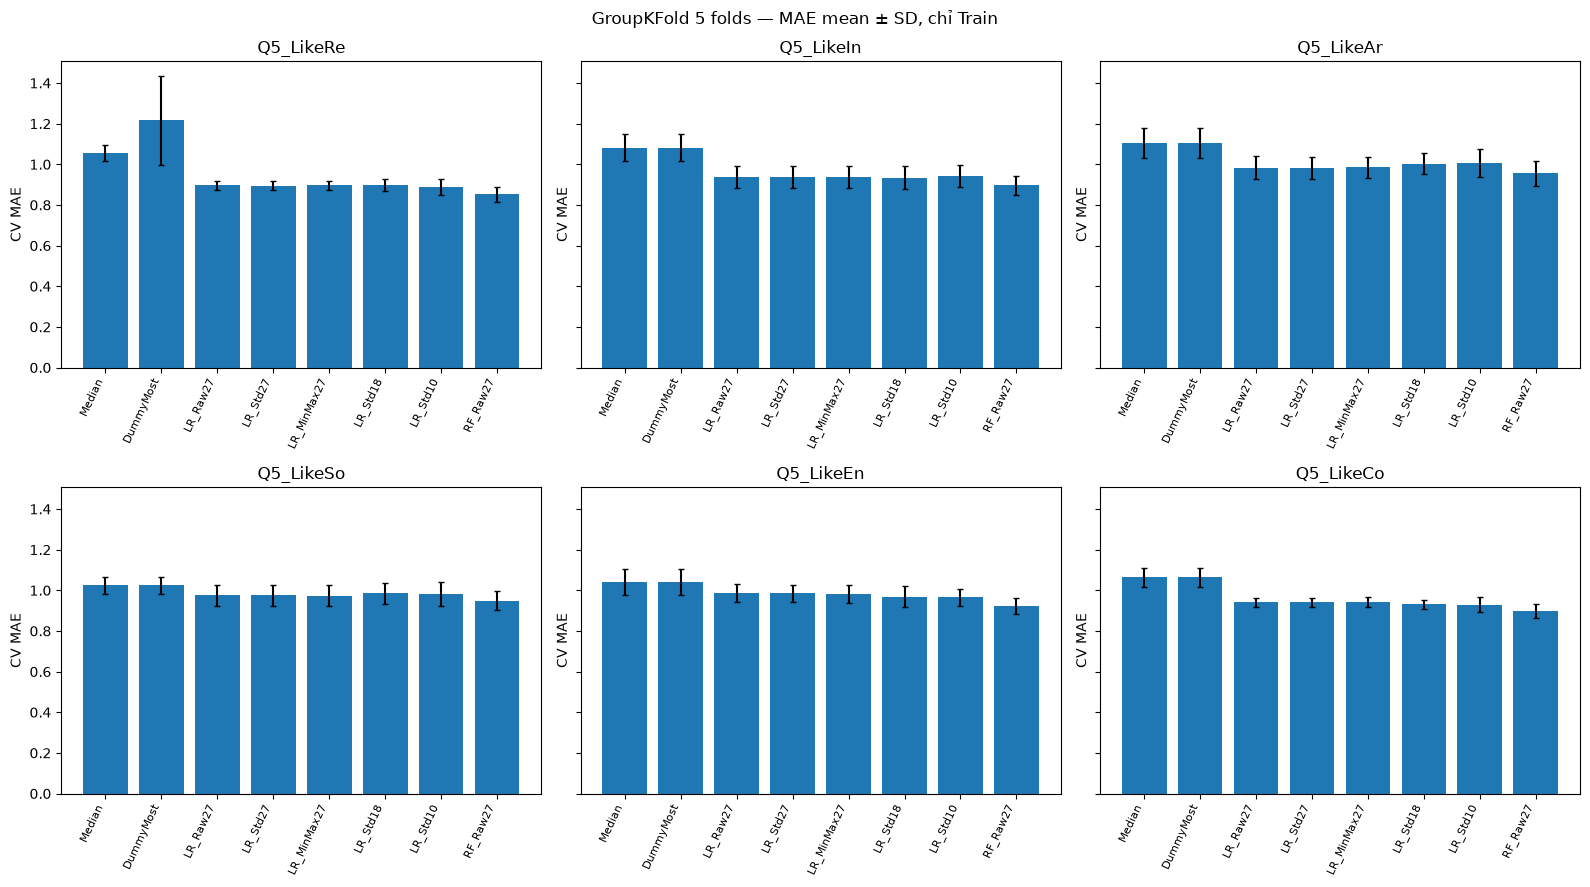

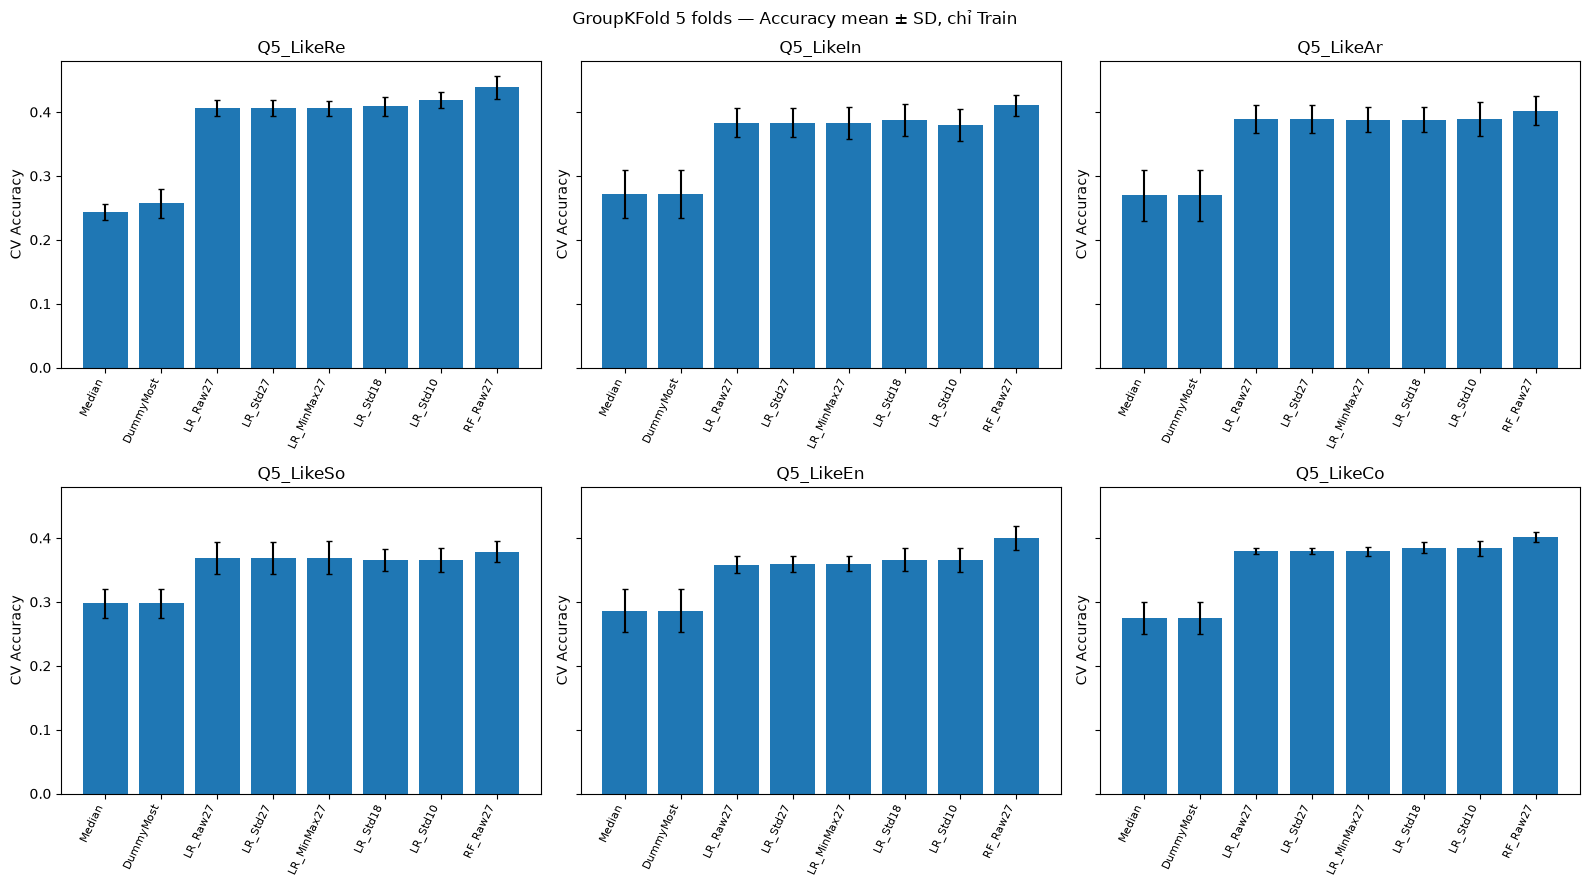

In [12]:
import matplotlib.pyplot as plt
for metric in ['MAE','Accuracy']:
    fig,axes=plt.subplots(2,3,figsize=(16,9),sharey=True)
    for ax,target in zip(axes.flat,q5_columns):
        view=summary[summary['Q5']==target].set_index('ID').loc[config_ids]
        ax.bar(range(8),view[metric+' mean'],yerr=view[metric+' SD'],capsize=2)
        ax.set_xticks(range(8),config_ids,rotation=65,ha='right',fontsize=8)
        ax.set(title=target,ylabel='CV '+metric)
        ax.set_ylim(bottom=0)
    fig.suptitle('GroupKFold 5 folds — '+metric+' mean ± SD, chỉ Train')
    plt.tight_layout()
    plt.show()

## Bước 10: Đánh giá hạn chế của bài toán 5 mức
- Kết luận: Độ chính xác 5 mức chỉ đạt ~41% do mức trung dung (mức 3) có độ bất định cao.

In [13]:
assert X_train.equals(X_snapshot) and y_train.equals(y_snapshot)
assert X_train.shape==(3963,27) and y_train.shape==(3963,6) and groups_train.nunique()==3568
assert list(X_train.columns)==question_columns and list(y_train.columns)==q5_columns
assert not set(q5_columns+['SOURCE_ROW']).intersection(X_train.columns)
assert hashlib.sha256(np.asarray(X_train.index,dtype='<i8').tobytes()).hexdigest()==train_index_sha256
assert 'X_test' not in globals() and 'y_test' not in globals()
assert 'raw_survey' not in globals() and 'survey_int' not in globals()
assert cv_fit_count==240 and full_train_fit_count==6
assert set(chosen_ids)==set(q5_columns) and len(selected_metadata)==6
pd.testing.assert_frame_equal(raw_codebook,original_codebook)
sha_after=hashlib.sha256(workbook_path.read_bytes()).hexdigest()
assert sha_before==sha_after
print('PASS: 240 fit CV tách group, 6 fit chẩn đoán full Train; Test chưa dùng đánh giá/chọn mô hình.')
print('SHA-256 workbook:',sha_after)


PASS: 240 fit CV tách group, 6 fit chẩn đoán full Train; Test chưa dùng đánh giá/chọn mô hình.
SHA-256 workbook: c8a9445edba02a37cf862a3b1eabffba910eb7eeaf1d48b4c6f8ac19fea296c8


# PHẦN MỞ RỘNG 1: TỐI ƯU HÓA XGBOOST CHO SÁU BIẾN Q5
## Bước 11: Mở rộng không gian đặc trưng và cấu hình Folds
- Đầu vào: 27 câu hỏi gốc và 6 đặc trưng trung bình nhóm RIASEC.

In [14]:
import xgboost as ext_xgb
import scipy as ext_scipy
import sklearn as ext_sklearn
import time as ext_time
import warnings as ext_warnings
from sklearn.model_selection import GroupKFold as ExtGroupKFold
from sklearn.base import clone as ext_clone
from sklearn.ensemble import RandomForestClassifier as ExtRandomForest
from sklearn.metrics import mean_absolute_error as ext_mae,accuracy_score as ext_accuracy
from sklearn.metrics import f1_score as ext_f1,balanced_accuracy_score as ext_balanced
from sklearn.exceptions import ConvergenceWarning as ExtConvergenceWarning
assert sys.version_info[:3]==(3,14,7)
assert Path(sys.executable).resolve()==Path('C:/Users/DELL/AppData/Local/Programs/Python/Python314/python.exe').resolve()
assert ext_xgb.__version__=='3.4.1'
assert (np.__version__,ext_scipy.__version__,ext_sklearn.__version__,pd.__version__)==('2.5.3','1.18.1','1.9.1','3.0.6')
print('Interpreter:',sys.executable)
print('Python/XGB/NumPy/SciPy/sklearn/pandas:',sys.version.split()[0],ext_xgb.__version__,np.__version__,ext_scipy.__version__,ext_sklearn.__version__,pd.__version__)
assert X_train.shape==(3963,27) and y_train.shape==(3963,6) and groups_train.nunique()==3568
assert list(X_train.columns)==question_columns and list(y_train.columns)==q5_columns
assert not set(q5_columns+['SOURCE_ROW']).intersection(X_train.columns)
assert X_train.index.equals(y_train.index) and X_train.index.equals(groups_train.index)
assert X_train.isin(range(1,6)).all().all() and y_train.isin(range(1,6)).all().all()
assert 'X_test' not in globals() and 'y_test' not in globals()
assert hashlib.sha256(np.asarray(X_train.index,dtype='<i8').tobytes()).hexdigest()=='471fecbbc5d665e949eae03bcdebedc996044f30136a56d8b1d698ad3d7e2d4d'
ext_sha_before=hashlib.sha256(workbook_path.read_bytes()).hexdigest()
assert ext_sha_before=='c8a9445edba02a37cf862a3b1eabffba910eb7eeaf1d48b4c6f8ac19fea296c8'
ext_X_snapshot=X_train.copy(deep=True)
ext_y_snapshot=y_train.copy(deep=True)
ext_groups_snapshot=groups_train.copy(deep=True)


Interpreter: C:\Users\DELL\AppData\Local\Programs\Python\Python314\python.exe
Python/XGB/NumPy/SciPy/sklearn/pandas: 3.14.7 3.4.1 2.5.3 1.18.1 1.9.1 3.0.6


In [15]:
ext_group_map={'R':['R1','R2','R3','R4','R5'],'I':['I1','I2','I3','I4'],
 'A':['A1','A2','A3','A4','A5'],'S':['S1','S2','S3','S4'],
 'E':['E1','E2','E3','E4','E5'],'C':['C1','C2','C3','C4']}
assert len([q for cols in ext_group_map.values() for q in cols])==27
assert set(q for cols in ext_group_map.values() for q in cols)==set(question_columns)
ext_augmented=X_train.copy(deep=True)
for ext_key,ext_cols in ext_group_map.items():
    ext_augmented['Mean_'+ext_key]=X_train[ext_cols].mean(axis=1)
ext_views={'Raw27':X_train.copy(deep=True),'Raw27Means':ext_augmented}
assert ext_augmented.shape==(3963,33) and ext_augmented.iloc[:,:27].equals(X_train)
assert ext_augmented.index.equals(y_train.index) and np.isfinite(ext_augmented.to_numpy()).all()
assert not set(q5_columns+['SOURCE_ROW']).intersection(ext_augmented.columns)
print('Raw27Means feature order:',ext_augmented.columns.tolist())
ext_folds=list(ExtGroupKFold(n_splits=5).split(X_train,groups=groups_train))
if 'folds' in globals():
    assert len(folds)==5
    for ext_old,ext_new in zip(folds,ext_folds):
        assert np.array_equal(ext_old[0],ext_new[0]) and np.array_equal(ext_old[1],ext_new[1])
ext_fold_rows=[]
ext_support_rows=[]
ext_seen=[]
for ext_fold,(ext_tr,ext_va) in enumerate(ext_folds,1):
    assert len(ext_tr)+len(ext_va)==3963 and set(ext_tr).isdisjoint(ext_va)
    assert set(groups_train.iloc[ext_tr]).isdisjoint(groups_train.iloc[ext_va])
    assert set(SOURCE_ROW_train.iloc[ext_tr]).isdisjoint(SOURCE_ROW_train.iloc[ext_va])
    assert set(X_train.iloc[ext_tr].itertuples(index=False,name=None)).isdisjoint(X_train.iloc[ext_va].itertuples(index=False,name=None))
    ext_seen.extend(ext_va)
    ext_fold_rows.append({'Fold':ext_fold,'Training n':len(ext_tr),'Validation n':len(ext_va),
      'Training groups':groups_train.iloc[ext_tr].nunique(),'Validation groups':groups_train.iloc[ext_va].nunique(),
      'Validation index SHA256':hashlib.sha256(np.asarray(X_train.iloc[ext_va].index,dtype='<i8').tobytes()).hexdigest()})
    for ext_target in q5_columns:
        ext_a=y_train[ext_target].iloc[ext_tr].value_counts().reindex(range(1,6),fill_value=0)
        ext_v=y_train[ext_target].iloc[ext_va].value_counts().reindex(range(1,6),fill_value=0)
        ext_support_rows.append({'Q5':ext_target,'Fold':ext_fold,'Train mức 1–5':ext_a.tolist(),'Valid mức 1–5':ext_v.tolist()})
        if not ext_a.gt(0).all() or not ext_v.gt(0).all():
            display(pd.DataFrame(ext_support_rows))
            raise RuntimeError('Fold thiếu mức: dừng, không đổi seed hoặc nhãn.')
assert sorted(ext_seen)==list(range(3963))
display(pd.DataFrame(ext_fold_rows))
display(pd.DataFrame(ext_support_rows))

Raw27Means feature order: ['R1', 'I1', 'A1', 'R2', 'I2', 'A2', 'S1', 'S2', 'R3', 'A3', 'S3', 'E1', 'R4', 'S4', 'E2', 'R5', 'I3', 'A4', 'E3', 'I4', 'A5', 'E4', 'C1', 'E5', 'C2', 'C3', 'C4', 'Mean_R', 'Mean_I', 'Mean_A', 'Mean_S', 'Mean_E', 'Mean_C']


   Fold  Training n  Validation n  Training groups  Validation groups                                           Validation index SHA256
0     1        3170           793             2962                606  effeaaaac5f88614c29251271650398786cab914e97c7faaf10041626b115417
1     2        3170           793             2834                734  85457c115693c48f5bef34be42cb8e05f62446346018e37bbd9e8cd3d7c9d5c8
2     3        3170           793             2827                741  faa43040c9f45d5d20392f58a91712d6006bd0c789b9b71502d90888566b8d86
3     4        3171           792             2825                743  cf9546027ec629cbcd6ad02740af1982268a9a2d3da51ca4ba5f4fae0a763c0c
4     5        3171           792             2824                744  03b1a8208566c8781f079cd516a7e4b74bd1ee18e2ae63e9667c88cf5db044c3

           Q5  Fold              Train mức 1–5              Valid mức 1–5
0   Q5_LikeRe     1  [915, 769, 843, 338, 305]    [177, 194, 260, 89, 73]
1   Q5_LikeIn     1  [727, 690, 811, 512, 430]   [146, 157, 268, 125, 97]
2   Q5_LikeAr     1  [616, 588, 801, 547, 618]  [131, 146, 267, 130, 119]
3   Q5_LikeSo     1  [606, 670, 917, 530, 447]   [129, 159, 262, 146, 97]
4   Q5_LikeEn     1  [632, 639, 862, 584, 453]   [116, 155, 272, 153, 97]
5   Q5_LikeCo     1  [734, 713, 837, 517, 369]   [150, 164, 252, 141, 86]
6   Q5_LikeRe     2  [879, 783, 884, 341, 283]    [213, 180, 219, 86, 95]
7   Q5_LikeIn     2  [704, 666, 874, 517, 409]  [169, 181, 205, 120, 118]
8   Q5_LikeAr     2  [589, 580, 879, 540, 582]  [158, 154, 189, 137, 155]
9   Q5_LikeSo     2  [585, 660, 964, 535, 426]  [150, 169, 215, 141, 118]
10  Q5_LikeEn     2  [588, 648, 926, 571, 437]  [160, 146, 208, 166, 113]
11  Q5_LikeCo     2  [708, 705, 875, 525, 357]   [176, 172, 214, 133, 98]
12  Q5_LikeRe     3  [845, 769, 906, 3

## Bước 12: Thiết lập lưới siêu tham số cho XGBoost
- Tham số: `learning_rate=0.05`, `max_depth`, `reg_lambda=4`, `subsample=0.85`.

In [16]:
ext_common={'learning_rate':.05,'subsample':.85,'colsample_bytree':.85,'reg_lambda':4,
 'tree_method':'hist','random_state':42,'n_jobs':1}
ext_specs=[('XGBC_d2','XGBC',2,160,'Raw27'),('XGBC_d3','XGBC',3,200,'Raw27'),
 ('XGBC_d3_means','XGBC',3,200,'Raw27Means'),('XGBR_d2','XGBR',2,200,'Raw27'),
 ('XGBR_d3','XGBR',3,200,'Raw27'),('XGBR_d3_means','XGBR',3,200,'Raw27Means'),
 ('RF_reference','RF',10,100,'Raw27')]
ext_configs=[]
for ext_id,ext_family,ext_depth,ext_trees,ext_features in ext_specs:
    if ext_family=='XGBC':
        ext_template=ext_xgb.XGBClassifier(**ext_common,max_depth=ext_depth,n_estimators=ext_trees,
            objective='multi:softprob',eval_metric='mlogloss')
    elif ext_family=='XGBR':
        ext_template=ext_xgb.XGBRegressor(**ext_common,max_depth=ext_depth,n_estimators=ext_trees,objective='reg:squarederror')
    else:
        ext_template=ExtRandomForest(n_estimators=100,max_depth=10,min_samples_leaf=5,max_features='sqrt',random_state=42,n_jobs=1)
    ext_configs.append({'ID':ext_id,'Family':ext_family,'Features':ext_features,
        'depth':ext_depth,'trees':ext_trees,'Model':ext_template})
display(pd.DataFrame([{k:v for k,v in cfg.items() if k!='Model'} for cfg in ext_configs]))
for ext_cfg in ext_configs:print(ext_cfg['ID'],ext_cfg['Model'].get_params())


XGBC_d2 {'objective': 'multi:softprob', 'base_score': None, 'booster': None, 'callbacks': None, 'colsample_bylevel': None, 'colsample_bynode': None, 'colsample_bytree': 0.85, 'device': None, 'early_stopping_rounds': None, 'enable_categorical': True, 'eval_metric': 'mlogloss', 'feature_types': None, 'feature_weights': None, 'gamma': None, 'grow_policy': None, 'importance_type': None, 'interaction_constraints': None, 'learning_rate': 0.05, 'max_bin': None, 'max_cat_threshold': None, 'max_cat_to_onehot': None, 'max_delta_step': None, 'max_depth': 2, 'max_leaves': None, 'min_child_weight': None, 'missing': nan, 'monotone_constraints': None, 'multi_strategy': None, 'n_estimators': 160, 'n_jobs': 1, 'num_parallel_tree': None, 'random_state': 42, 'reg_alpha': None, 'reg_lambda': 4, 'sampling_method': None, 'scale_pos_weight': None, 'subsample': 0.85, 'tree_method': 'hist', 'validate_parameters': None, 'verbosity': None}
XGBC_d3 {'objective': 'multi:softprob', 'base_score': None, 'booster': No

              ID Family    Features  depth  trees
0        XGBC_d2   XGBC       Raw27      2    160
1        XGBC_d3   XGBC       Raw27      3    200
2  XGBC_d3_means   XGBC  Raw27Means      3    200
3        XGBR_d2   XGBR       Raw27      2    200
4        XGBR_d3   XGBR       Raw27      3    200
5  XGBR_d3_means   XGBR  Raw27Means      3    200
6   RF_reference     RF       Raw27     10    100

## Bước 13: Huấn luyện XGBoost trên 5 Folds Cross-Validation
- Thực thi: 35 cấu hình XGBoost trên từng biến Q5.

In [17]:
ext_rows=[]
ext_fit_log=[]
ext_warning_rows=[]
def ext_metric_row(target,config,rule,fold,truth,prediction,convergence):
    prediction=np.asarray(prediction,dtype='int64')
    assert prediction.shape==truth.shape and np.isin(prediction,[1,2,3,4,5]).all()
    return {'Q5':target,'Config':config['ID'],'Eval_ID':config['ID']+'::'+rule,'Rule':rule,
      'Family':config['Family'],'Features':config['Features'],'n_features':ext_views[config['Features']].shape[1],
      'depth':config['depth'],'trees':config['trees'],'Fold':fold,'Validation n':len(truth),
      'MAE':ext_mae(truth,prediction),'Accuracy':ext_accuracy(truth,prediction),
      'Macro-F1':ext_f1(truth,prediction,labels=[1,2,3,4,5],average='macro',zero_division=0),
      'Balanced Accuracy':ext_balanced(truth,prediction),'ConvergenceWarning':convergence}
for ext_target in q5_columns:
    print('XGB extension target:',ext_target,flush=True)
    for ext_cfg in ext_configs:
        print('  Fit config:',ext_cfg['ID'],flush=True)
        ext_data=ext_views[ext_cfg['Features']]
        for ext_fold,(ext_tr,ext_va) in enumerate(ext_folds,1):
            ext_model=ext_clone(ext_cfg['Model'])
            ext_label=y_train[ext_target].iloc[ext_tr]
            ext_truth=y_train[ext_target].iloc[ext_va].to_numpy()
            ext_started=ext_time.perf_counter()
            with ext_warnings.catch_warnings(record=True) as ext_caught:
                ext_warnings.simplefilter('always')
                ext_model.fit(ext_data.iloc[ext_tr],ext_label-1 if ext_cfg['Family']=='XGBC' else ext_label)
                if ext_cfg['Family']=='XGBC':
                    ext_proba=ext_model.predict_proba(ext_data.iloc[ext_va])
                else:
                    ext_raw_prediction=np.asarray(ext_model.predict(ext_data.iloc[ext_va]))
            ext_fit_log.append({'Q5':ext_target,'Config':ext_cfg['ID'],'Fold':ext_fold,
                'Training n':len(ext_tr),'Validation n':len(ext_va),'Fit/predict seconds':ext_time.perf_counter()-ext_started})
            assert ext_model.n_features_in_==ext_data.shape[1]
            ext_convergence=any(issubclass(w.category,ExtConvergenceWarning) for w in ext_caught)
            for ext_w in ext_caught:
                ext_warning_rows.append({'Q5':ext_target,'Config':ext_cfg['ID'],'Fold':ext_fold,'Category':ext_w.category.__name__,'Message':str(ext_w.message)})
            if ext_cfg['Family']=='XGBC':
                ext_classes=np.asarray(ext_model.classes_,dtype='int64')
                assert np.array_equal(ext_classes,np.arange(5))
                assert ext_proba.shape==(len(ext_va),5) and np.isfinite(ext_proba).all()
                assert (ext_proba>=0).all() and (ext_proba<=1).all()
                assert np.allclose(ext_proba.sum(axis=1),1,atol=1e-5)
                ext_levels=ext_classes+1
                ext_pred_argmax=ext_levels[np.argmax(ext_proba,axis=1)]
                ext_cdf=np.cumsum(ext_proba,axis=1)
                assert (ext_cdf>=.5).any(axis=1).all()
                ext_pred_median=ext_levels[np.argmax(ext_cdf>=.5,axis=1)]
                ext_rows.append(ext_metric_row(ext_target,ext_cfg,'argmax',ext_fold,ext_truth,ext_pred_argmax,ext_convergence))
                ext_rows.append(ext_metric_row(ext_target,ext_cfg,'median_probability',ext_fold,ext_truth,ext_pred_median,ext_convergence))
            else:
                assert ext_raw_prediction.shape==(len(ext_va),) and np.isfinite(ext_raw_prediction).all()
                if ext_cfg['Family']=='XGBR':
                    ext_prediction=np.clip(np.floor(ext_raw_prediction+.5),1,5).astype('int64')
                    ext_rule='round_half_up_clip'
                else:
                    assert np.equal(ext_raw_prediction,np.rint(ext_raw_prediction)).all()
                    ext_prediction=ext_raw_prediction.astype('int64')
                    ext_rule='predict'
                ext_rows.append(ext_metric_row(ext_target,ext_cfg,ext_rule,ext_fold,ext_truth,ext_prediction,ext_convergence))
            del ext_model
ext_results=pd.DataFrame(ext_rows)
ext_fit_table=pd.DataFrame(ext_fit_log)
assert len(ext_fit_table)==210 and len(ext_results)==300
assert ext_fit_table.groupby(['Q5','Config']).size().eq(5).all()
assert ext_results.groupby(['Q5','Eval_ID']).size().eq(5).all()
print('Fits:',len(ext_fit_table),'XGB:',int(ext_fit_table['Config'].str.startswith('XGB').sum()),'RF:',int(ext_fit_table['Config'].eq('RF_reference').sum()))
print('Warnings:',len(ext_warning_rows))
if ext_warning_rows:display(pd.DataFrame(ext_warning_rows))
display(ext_results)

XGB extension target: Q5_LikeRe
  Fit config: XGBC_d2
  Fit config: XGBC_d3
  Fit config: XGBC_d3_means
  Fit config: XGBR_d2
  Fit config: XGBR_d3
  Fit config: XGBR_d3_means
  Fit config: RF_reference
XGB extension target: Q5_LikeIn
  Fit config: XGBC_d2
  Fit config: XGBC_d3
  Fit config: XGBC_d3_means
  Fit config: XGBR_d2
  Fit config: XGBR_d3
  Fit config: XGBR_d3_means
  Fit config: RF_reference
XGB extension target: Q5_LikeAr
  Fit config: XGBC_d2
  Fit config: XGBC_d3
  Fit config: XGBC_d3_means
  Fit config: XGBR_d2
  Fit config: XGBR_d3
  Fit config: XGBR_d3_means
  Fit config: RF_reference
XGB extension target: Q5_LikeSo
  Fit config: XGBC_d2
  Fit config: XGBC_d3
  Fit config: XGBC_d3_means
  Fit config: XGBR_d2
  Fit config: XGBR_d3
  Fit config: XGBR_d3_means
  Fit config: RF_reference
XGB extension target: Q5_LikeEn
  Fit config: XGBC_d2
  Fit config: XGBC_d3
  Fit config: XGBC_d3_means
  Fit config: XGBR_d2
  Fit config: XGBR_d3
  Fit config: XGBR_d3_means
  Fit config

            Q5         Config                            Eval_ID                Rule Family    Features  n_features  depth  trees  Fold  Validation n       MAE  Accuracy  Macro-F1  Balanced Accuracy  ConvergenceWarning
0    Q5_LikeRe        XGBC_d2                    XGBC_d2::argmax              argmax   XGBC       Raw27          27      2    160     1           793  0.849937  0.443884  0.344725           0.362192               False
1    Q5_LikeRe        XGBC_d2        XGBC_d2::median_probability  median_probability   XGBC       Raw27          27      2    160     1           793  0.770492  0.440101  0.338281           0.339925               False
2    Q5_LikeRe        XGBC_d2                    XGBC_d2::argmax              argmax   XGBC       Raw27          27      2    160     2           793  0.900378  0.403531  0.334175           0.336866               False
3    Q5_LikeRe        XGBC_d2        XGBC_d2::median_probability  median_probability   XGBC       Raw27          27      2  

## Bước 14: Tổng hợp kết quả các biến thể XGBoost
- Bảng tổng hợp: So sánh quy tắc gán nhãn `predict` và `argmax`.

In [18]:
ext_group_columns=['Q5','Eval_ID','Config','Rule','Family','Features','n_features','depth','trees']
ext_summary=ext_results.groupby(ext_group_columns,sort=False)[['MAE','Accuracy','Macro-F1','Balanced Accuracy']].agg(['mean','std'])
ext_summary.columns=[metric+' '+('SD' if agg=='std' else agg) for metric,agg in ext_summary.columns]
ext_summary=ext_summary.reset_index()
ext_summary['Folds']=5
ext_warning_flags=ext_results.groupby(['Q5','Eval_ID'])['ConvergenceWarning'].any()
ext_summary['Eligible']=[not bool(ext_warning_flags.loc[(row.Q5,row.Eval_ID)]) for row in ext_summary.itertuples()]
assert len(ext_summary)==60
display(ext_summary.sort_values(['Q5','MAE mean']).round(6))
ext_rf_current=ext_summary[ext_summary['Family']=='RF'].set_index('Q5').loc[q5_columns]
ext_rf_historical=pd.DataFrame([[.852373,.438560],[.897800,.410550],[.956611,.402217],
 [.949777,.378755],[.922270,.400209],[.898546,.401464]],index=q5_columns,columns=['MAE mean','Accuracy mean'])
assert np.allclose(ext_rf_current[['MAE mean','Accuracy mean']],ext_rf_historical,atol=5e-7,rtol=0)
ext_rf_recheck=ext_rf_historical.add_suffix(' lịch sử').join(ext_rf_current[['MAE mean','Accuracy mean']].add_suffix(' chạy lại'))
display(ext_rf_recheck.round(6))
print('PASS: RF khớp kết quả lịch sử trên cùng folds.')

PASS: RF khớp kết quả lịch sử trên cùng folds.


           Q5                            Eval_ID         Config                Rule Family    Features  n_features  depth  trees  MAE mean    MAE SD  Accuracy mean  Accuracy SD  Macro-F1 mean  Macro-F1 SD  Balanced Accuracy mean  Balanced Accuracy SD  Folds  Eligible
25  Q5_LikeAr  XGBC_d3_means::median_probability  XGBC_d3_means  median_probability   XGBC  Raw27Means          33      3    200  0.865764  0.036773       0.376227     0.017462       0.351093     0.011965                0.349990              0.009484      5      True
23  Q5_LikeAr        XGBC_d3::median_probability        XGBC_d3  median_probability   XGBC       Raw27          27      3    200  0.869291  0.032539       0.371434     0.013465       0.345931     0.008812                0.345300              0.011663      5      True
21  Q5_LikeAr        XGBC_d2::median_probability        XGBC_d2  median_probability   XGBC       Raw27          27      2    160  0.876355  0.034859       0.363108     0.012888       0.330479     

           MAE mean lịch sử  Accuracy mean lịch sử  MAE mean chạy lại  Accuracy mean chạy lại
Q5_LikeRe          0.852373               0.438560           0.852373                0.438560
Q5_LikeIn          0.897800               0.410550           0.897800                0.410550
Q5_LikeAr          0.956611               0.402217           0.956611                0.402217
Q5_LikeSo          0.949777               0.378755           0.949777                0.378755
Q5_LikeEn          0.922270               0.400209           0.922270                0.400209
Q5_LikeCo          0.898546               0.401464           0.898546                0.401464

## Bước 15: So sánh đối đầu: Random Forest vs XGBoost
- So sánh: Hiệu năng tốt nhất giữa hai thuật toán Ensemble trên 6 biến Q5.

In [19]:
ext_best_rows=[]
ext_pair_rows=[]
ext_chosen={}
for ext_target in q5_columns:
    ext_candidates=ext_summary[(ext_summary['Q5']==ext_target)&(ext_summary['Family']!='RF')&ext_summary['Eligible']]
    if ext_candidates.empty:raise RuntimeError('Không có XGB hợp lệ cho '+ext_target)
    ext_best=ext_candidates.sort_values(['MAE mean','Macro-F1 mean','MAE SD','n_features','depth','trees','Eval_ID'],
        ascending=[True,False,True,True,True,True,True],kind='stable').iloc[0]
    ext_chosen[ext_target]=ext_best['Eval_ID']
    ext_rf=ext_rf_current.loc[ext_target]
    ext_rf_fold=ext_results[(ext_results['Q5']==ext_target)&(ext_results['Family']=='RF')].set_index('Fold')
    ext_xgb_fold=ext_results[(ext_results['Q5']==ext_target)&(ext_results['Eval_ID']==ext_best['Eval_ID'])].set_index('Fold')
    assert ext_rf_fold.index.equals(ext_xgb_fold.index)
    ext_delta=ext_rf_fold['MAE']-ext_xgb_fold['MAE']
    ext_best_rows.append({'Q5':ext_target,'XGB candidate':ext_best['Eval_ID'],'n_features':int(ext_best['n_features']),
       'RF CV MAE':ext_rf['MAE mean'],'RF MAE SD':ext_rf['MAE SD'],'XGB CV MAE':ext_best['MAE mean'],'XGB MAE SD':ext_best['MAE SD'],
       'Cải thiện %':(ext_rf['MAE mean']-ext_best['MAE mean'])/ext_rf['MAE mean']*100,
       'RF Accuracy':ext_rf['Accuracy mean'],'XGB Accuracy':ext_best['Accuracy mean'],'XGB Accuracy SD':ext_best['Accuracy SD'],
       'XGB Macro-F1':ext_best['Macro-F1 mean'],'XGB Balanced Accuracy':ext_best['Balanced Accuracy mean'],
       'Số fold XGB tốt hơn':int(ext_delta.gt(0).sum()),'Fold bằng nhau':int(ext_delta.eq(0).sum()),
       'Giảm MAE mean':ext_delta.mean(),'Giảm MAE SD':ext_delta.std(ddof=1)})
    for ext_fold in range(1,6):
        ext_pair_rows.append({'Q5':ext_target,'Fold':ext_fold,'RF MAE':ext_rf_fold.loc[ext_fold,'MAE'],
          'XGB MAE':ext_xgb_fold.loc[ext_fold,'MAE'],'RF - XGB MAE':ext_delta.loc[ext_fold]})
    ext_selected_cfg=next(cfg for cfg in ext_configs if cfg['ID']==ext_best['Config'])
    print('ỨNG VIÊN CV:',ext_target,ext_best['Eval_ID'],'; chưa kiểm chứng độc lập mới.')
    print('Params:',ext_selected_cfg['Model'].get_params())
    print('Features:',ext_selected_cfg['Features'],'Rule:',ext_best['Rule'])
ext_comparison=pd.DataFrame(ext_best_rows)
ext_paired=pd.DataFrame(ext_pair_rows)
display(ext_comparison.round(6))
display(ext_paired.round(6))

ỨNG VIÊN CV: Q5_LikeRe XGBC_d2::median_probability ; chưa kiểm chứng độc lập mới.
Params: {'objective': 'multi:softprob', 'base_score': None, 'booster': None, 'callbacks': None, 'colsample_bylevel': None, 'colsample_bynode': None, 'colsample_bytree': 0.85, 'device': None, 'early_stopping_rounds': None, 'enable_categorical': True, 'eval_metric': 'mlogloss', 'feature_types': None, 'feature_weights': None, 'gamma': None, 'grow_policy': None, 'importance_type': None, 'interaction_constraints': None, 'learning_rate': 0.05, 'max_bin': None, 'max_cat_threshold': None, 'max_cat_to_onehot': None, 'max_delta_step': None, 'max_depth': 2, 'max_leaves': None, 'min_child_weight': None, 'missing': nan, 'monotone_constraints': None, 'multi_strategy': None, 'n_estimators': 160, 'n_jobs': 1, 'num_parallel_tree': None, 'random_state': 42, 'reg_alpha': None, 'reg_lambda': 4, 'sampling_method': None, 'scale_pos_weight': None, 'subsample': 0.85, 'tree_method': 'hist', 'validate_parameters': None, 'verbosity

          Q5                      XGB candidate  n_features  RF CV MAE  RF MAE SD  XGB CV MAE  XGB MAE SD  Cải thiện %  RF Accuracy  XGB Accuracy  XGB Accuracy SD  XGB Macro-F1  XGB Balanced Accuracy  Số fold XGB tốt hơn  Fold bằng nhau  Giảm MAE mean  Giảm MAE SD
0  Q5_LikeRe        XGBC_d2::median_probability          27   0.852373   0.037019    0.791561    0.031536     7.134483     0.438560      0.417614         0.018019      0.346310               0.348694                    5               0       0.060812     0.018904
1  Q5_LikeIn        XGBC_d3::median_probability          27   0.897800   0.046817    0.831683    0.042321     7.364373     0.410550      0.384562         0.025018      0.345734               0.348229                    5               0       0.066117     0.033724
2  Q5_LikeAr  XGBC_d3_means::median_probability          33   0.956611   0.061244    0.865764    0.036773     9.496789     0.402217      0.376227         0.017462      0.351093               0.349990      

           Q5  Fold    RF MAE   XGB MAE  RF - XGB MAE
0   Q5_LikeRe     1  0.841110  0.770492      0.070618
1   Q5_LikeRe     2  0.914250  0.833544      0.080706
2   Q5_LikeRe     3  0.847415  0.815889      0.031526
3   Q5_LikeRe     4  0.814394  0.760101      0.054293
4   Q5_LikeRe     5  0.844697  0.777778      0.066919
5   Q5_LikeIn     1  0.844893  0.790668      0.054224
6   Q5_LikeIn     2  0.973518  0.878941      0.094578
7   Q5_LikeIn     3  0.892812  0.866330      0.026482
8   Q5_LikeIn     4  0.883838  0.835859      0.047980
9   Q5_LikeIn     5  0.893939  0.786616      0.107323
10  Q5_LikeAr     1  0.849937  0.802018      0.047919
11  Q5_LikeAr     2  0.993695  0.889029      0.104666
12  Q5_LikeAr     3  0.977301  0.885246      0.092055
13  Q5_LikeAr     4  0.963384  0.866162      0.097222
14  Q5_LikeAr     5  0.998737  0.886364      0.112374
15  Q5_LikeSo     1  0.902900  0.815889      0.087011
16  Q5_LikeSo     2  1.008827  0.916772      0.092055
17  Q5_LikeSo     3  0.97099

## Bước 16: Phân tích ảnh hưởng của đặc trưng trung bình nhóm
- Đánh giá: Đóng góp của 6 điểm trung bình nhóm vào không gian đặc trưng.

In [20]:
ext_effect_rows=[]
ext_rule_rows=[]
for ext_target in q5_columns:
    ext_by_id=ext_summary[ext_summary['Q5']==ext_target].set_index('Eval_ID')
    for ext_family,ext_rule in [('XGBC','argmax'),('XGBC','median_probability'),('XGBR','round_half_up_clip')]:
        for ext_effect,ext_left,ext_right in [('Thêm 6 mean',ext_family+'_d3',ext_family+'_d3_means'),('d2 so d3',ext_family+'_d2',ext_family+'_d3')]:
            ext_l=ext_by_id.loc[ext_left+'::'+ext_rule]
            ext_r=ext_by_id.loc[ext_right+'::'+ext_rule]
            ext_effect_rows.append({'Q5':ext_target,'So sánh':ext_effect,'Family':ext_family,'Rule':ext_rule,
               'Trước MAE':ext_l['MAE mean'],'Sau MAE':ext_r['MAE mean'],'Giảm MAE':ext_l['MAE mean']-ext_r['MAE mean'],
               'Trước Accuracy':ext_l['Accuracy mean'],'Sau Accuracy':ext_r['Accuracy mean'],
               'Đổi Accuracy (điểm %)':(ext_r['Accuracy mean']-ext_l['Accuracy mean'])*100})
    for ext_id in ['XGBC_d2','XGBC_d3','XGBC_d3_means']:
        ext_a=ext_by_id.loc[ext_id+'::argmax']
        ext_m=ext_by_id.loc[ext_id+'::median_probability']
        ext_rule_rows.append({'Q5':ext_target,'Config':ext_id,'Argmax MAE':ext_a['MAE mean'],'Median MAE':ext_m['MAE mean'],
           'Giảm MAE median':ext_a['MAE mean']-ext_m['MAE mean'],'Argmax Accuracy':ext_a['Accuracy mean'],
           'Median Accuracy':ext_m['Accuracy mean'],'Đổi Accuracy (điểm %)':(ext_m['Accuracy mean']-ext_a['Accuracy mean'])*100})
ext_effects=pd.DataFrame(ext_effect_rows)
ext_rule_comparison=pd.DataFrame(ext_rule_rows)
display(ext_effects.round(6))
display(ext_rule_comparison.round(6))
print('Median giảm MAE:',int(ext_rule_comparison['Giảm MAE median'].gt(0).sum()),'/18')
print('Median giảm MAE nhưng Accuracy cũng giảm:',int((ext_rule_comparison['Giảm MAE median'].gt(0)&ext_rule_comparison['Đổi Accuracy (điểm %)'].lt(0)).sum()),'/18')
print('MAE tốt nhất theo family riêng từng Q5:')
display(ext_summary[ext_summary['Family']!='RF'].groupby(['Q5','Family'])['MAE mean'].min().unstack().round(6))

Median giảm MAE: 18 /18
Median giảm MAE nhưng Accuracy cũng giảm: 18 /18
MAE tốt nhất theo family riêng từng Q5:


           Q5      So sánh Family                Rule  Trước MAE   Sau MAE  Giảm MAE  Trước Accuracy  Sau Accuracy  Đổi Accuracy (điểm %)
0   Q5_LikeRe  Thêm 6 mean   XGBC              argmax   0.852617  0.850608  0.002010        0.435785      0.435024              -0.076108
1   Q5_LikeRe     d2 so d3   XGBC              argmax   0.844794  0.852617 -0.007823        0.441593      0.435785              -0.580808
2   Q5_LikeRe  Thêm 6 mean   XGBC  median_probability   0.795852  0.797871 -0.002019        0.415342      0.415595               0.025316
3   Q5_LikeRe     d2 so d3   XGBC  median_probability   0.791561  0.795852 -0.004291        0.417614      0.415342              -0.227177
4   Q5_LikeRe  Thêm 6 mean   XGBR  round_half_up_clip   0.818568  0.826892 -0.008324        0.365628      0.358061              -0.756716
5   Q5_LikeRe     d2 so d3   XGBR  round_half_up_clip   0.823865  0.818568  0.005297        0.357809      0.365628               0.781873
6   Q5_LikeIn  Thêm 6 mean   XGBC 

           Q5         Config  Argmax MAE  Median MAE  Giảm MAE median  Argmax Accuracy  Median Accuracy  Đổi Accuracy (điểm %)
0   Q5_LikeRe        XGBC_d2    0.844794    0.791561         0.053234         0.441593         0.417614              -2.397907
1   Q5_LikeRe        XGBC_d3    0.852617    0.795852         0.056765         0.435785         0.415342              -2.044276
2   Q5_LikeRe  XGBC_d3_means    0.850608    0.797871         0.052737         0.435024         0.415595              -1.942852
3   Q5_LikeIn        XGBC_d2    0.916469    0.841270         0.075199         0.403488         0.373709              -2.977855
4   Q5_LikeIn        XGBC_d3    0.906637    0.831683         0.074954         0.406008         0.384562              -2.144650
5   Q5_LikeIn  XGBC_d3_means    0.902348    0.846823         0.055524         0.406262         0.379766              -2.649541
6   Q5_LikeAr        XGBC_d2    0.955349    0.876355         0.078994         0.404489         0.363108        

Family         XGBC      XGBR
Q5                           
Q5_LikeAr  0.865764  0.888218
Q5_LikeCo  0.833198  0.854649
Q5_LikeEn  0.870810  0.890999
Q5_LikeIn  0.831683  0.849607
Q5_LikeRe  0.791561  0.818568
Q5_LikeSo  0.879639  0.888216

## Bước 17: Đánh giá tổng kết phần mở rộng XGBoost
- Nhận xét: XGBoost cải thiện nhẹ nhưng bài toán 5 mức vẫn bị nghẽn ở mức 3.

In [21]:
assert len(ext_fit_table)==210 and len(ext_results)==300 and len(ext_summary)==60
assert X_train.equals(ext_X_snapshot) and y_train.equals(ext_y_snapshot) and groups_train.equals(ext_groups_snapshot)
assert X_train.shape==(3963,27) and y_train.shape==(3963,6) and groups_train.nunique()==3568
assert list(X_train.columns)==question_columns and list(y_train.columns)==q5_columns
assert set(ext_chosen)==set(q5_columns)
assert 'X_test' not in globals() and 'y_test' not in globals()
assert np.array_equal(ext_augmented[question_columns].to_numpy(),X_train.to_numpy())
assert np.isfinite(ext_results[['MAE','Accuracy','Macro-F1','Balanced Accuracy']].to_numpy()).all()
assert hashlib.sha256(workbook_path.read_bytes()).hexdigest()==ext_sha_before
assert (np.__version__,ext_scipy.__version__,ext_sklearn.__version__,pd.__version__)==('2.5.3','1.18.1','1.9.1','3.0.6')
print('PASS: 210 fit CV Train, hai rule classifier dùng cùng fit, không dùng Test/thay dữ liệu.')
print('Workbook SHA256:',ext_sha_before)
print('RF/Test lịch sử giữ nguyên; XGB chưa có kiểm chứng độc lập mới.')


PASS: 210 fit CV Train, hai rule classifier dùng cùng fit, không dùng Test/thay dữ liệu.
Workbook SHA256: c8a9445edba02a37cf862a3b1eabffba910eb7eeaf1d48b4c6f8ac19fea296c8
RF/Test lịch sử giữ nguyên; XGB chưa có kiểm chứng độc lập mới.


# PHẦN MỞ RỘNG 2: PHÂN LOẠI NHỊ PHÂN SỞ THÍCH (TRỌNG TÂM ĐỀ TÀI)
## Bước 18: Mã hóa nhãn nhị phân và lọc mẫu trung dung (Q5=3)
- Quy tắc nhãn: Mức 1, 2 = 0 (Không thích); Mức 4, 5 = 1 (Thích); Loại bỏ mức 3.
- Chống rò rỉ dữ liệu: Giữ nguyên phân chia Group 5-Fold trên tập Train 3.963 mẫu.

In [22]:
import sys,hashlib
import numpy as np,pandas as pd,sklearn as bin_sklearn,xgboost as bin_xgb
from sklearn.model_selection import GroupKFold as BinGroupKFold
from sklearn.pipeline import Pipeline as BinPipeline
from sklearn.base import clone as bin_clone
from sklearn.preprocessing import StandardScaler as BinStandardScaler
from sklearn.dummy import DummyClassifier as BinDummy
from sklearn.linear_model import LogisticRegression as BinLR
from sklearn.ensemble import RandomForestClassifier as BinRF
from sklearn.svm import SVC as BinSVC
from sklearn.neighbors import KNeighborsClassifier as BinKNN
from sklearn.metrics import accuracy_score as bin_accuracy,balanced_accuracy_score as bin_balanced
from sklearn.metrics import f1_score as bin_f1,recall_score as bin_recall,precision_score as bin_precision
from sklearn.metrics import confusion_matrix as bin_confusion
from sklearn.exceptions import ConvergenceWarning as BinConvergenceWarning
import warnings as bin_warnings
assert sys.version_info[:3]==(3,14,7)
assert Path(sys.executable).resolve()==Path('C:/Users/DELL/AppData/Local/Programs/Python/Python314/python.exe').resolve()
assert (np.__version__,pd.__version__,bin_sklearn.__version__,bin_xgb.__version__)==('2.5.3','3.0.6','1.9.1','3.4.1')
print('Python/Interpreter:',sys.version.split()[0],sys.executable)
print('NumPy/pandas/sklearn/XGB:',np.__version__,pd.__version__,bin_sklearn.__version__,bin_xgb.__version__)
assert X_train.shape==(3963,27) and y_train.shape==(3963,6) and groups_train.nunique()==3568
assert list(X_train.columns)==question_columns and list(y_train.columns)==q5_columns
assert X_train.index.equals(y_train.index) and X_train.index.equals(groups_train.index)
assert not set(q5_columns+['SOURCE_ROW']).intersection(X_train.columns)
assert X_train.isin(range(1,6)).all().all() and y_train.isin(range(1,6)).all().all()
assert 'X_test' not in globals() and 'y_test' not in globals()
assert hashlib.sha256(np.asarray(X_train.index,dtype='<i8').tobytes()).hexdigest()=='471fecbbc5d665e949eae03bcdebedc996044f30136a56d8b1d698ad3d7e2d4d'
bin_sha_before=hashlib.sha256(workbook_path.read_bytes()).hexdigest()
assert bin_sha_before=='c8a9445edba02a37cf862a3b1eabffba910eb7eeaf1d48b4c6f8ac19fea296c8'
bin_X_snapshot=X_train.copy(deep=True)
bin_y_snapshot=y_train.copy(deep=True)
bin_groups_snapshot=groups_train.copy(deep=True)


Python/Interpreter: 3.14.7 C:\Users\DELL\AppData\Local\Programs\Python\Python314\python.exe
NumPy/pandas/sklearn/XGB: 2.5.3 3.0.6 1.9.1 3.4.1


## Bước 19: Thiết lập Pipeline phân loại nhị phân (13 cấu hình)
- Mô hình: DummyMost, Logistic Regression (Raw, Std, MinMax), Random Forest, XGBoost.

In [23]:
bin_datasets={}
bin_coverage_rows=[]
bin_fold_rows=[]
for bin_target in q5_columns:
    bin_mask=y_train[bin_target].isin([1,2,4,5])
    bin_X=X_train.loc[bin_mask].copy()
    bin_y=y_train.loc[bin_mask,bin_target].ge(4).astype('int64')
    bin_g=groups_train.loc[bin_mask].copy()
    bin_source=SOURCE_ROW_train.loc[bin_mask].copy()
    assert bin_X.index.equals(bin_y.index) and bin_X.index.equals(bin_g.index)
    assert bin_X.index.equals(bin_source.index) and bin_source.is_unique
    assert set(bin_y.unique())=={0,1}
    assert len(bin_X)+int(y_train[bin_target].eq(3).sum())==3963
    assert np.array_equal(bin_y.to_numpy(),y_train.loc[bin_mask,bin_target].isin([4,5]).astype(int).to_numpy())
    bin_local_folds=list(BinGroupKFold(n_splits=5).split(bin_X,groups=bin_g))
    bin_seen=[]
    for bin_fold,(bin_tr,bin_va) in enumerate(bin_local_folds,1):
        assert set(bin_tr).isdisjoint(bin_va) and len(bin_tr)+len(bin_va)==len(bin_X)
        assert bin_X.iloc[bin_tr].index.intersection(bin_X.iloc[bin_va].index).empty
        assert set(bin_source.iloc[bin_tr]).isdisjoint(bin_source.iloc[bin_va])
        assert set(bin_g.iloc[bin_tr]).isdisjoint(bin_g.iloc[bin_va])
        assert set(bin_X.iloc[bin_tr].itertuples(index=False,name=None)).isdisjoint(bin_X.iloc[bin_va].itertuples(index=False,name=None))
        bin_train_counts=bin_y.iloc[bin_tr].value_counts().reindex([0,1],fill_value=0)
        bin_valid_counts=bin_y.iloc[bin_va].value_counts().reindex([0,1],fill_value=0)
        bin_fold_rows.append({'Q5':bin_target,'Fold':bin_fold,'Train n':len(bin_tr),'Validation n':len(bin_va),
            'Train 0':int(bin_train_counts[0]),'Train 1':int(bin_train_counts[1]),
            'Valid 0':int(bin_valid_counts[0]),'Valid 1':int(bin_valid_counts[1]),
            'Train groups':bin_g.iloc[bin_tr].nunique(),'Valid groups':bin_g.iloc[bin_va].nunique(),
            'Validation index SHA256':hashlib.sha256(np.asarray(bin_X.iloc[bin_va].index,dtype='<i8').tobytes()).hexdigest()})
        if not bin_train_counts.gt(0).all() or not bin_valid_counts.gt(0).all():
            display(pd.DataFrame(bin_fold_rows))
            raise RuntimeError('Binary fold thiếu lớp; dừng, không sửa nhãn/group/seed.')
        assert len(bin_tr)>=11
        bin_seen.extend(bin_va)
    assert sorted(bin_seen)==list(range(len(bin_X)))
    bin_datasets[bin_target]={'X':bin_X,'y':bin_y,'groups':bin_g,'SOURCE_ROW':bin_source,'folds':bin_local_folds}
    bin_counts=bin_y.value_counts().reindex([0,1],fill_value=0)
    bin_coverage_rows.append({'Q5':bin_target,'Train gốc':3963,'Binary n':len(bin_X),
        'Trung lập không tham gia':int((~bin_mask).sum()),'Coverage (%)':len(bin_X)/3963*100,
        'Không thích n':int(bin_counts[0]),'Thích n':int(bin_counts[1]),'Thích (%)':bin_y.mean()*100,
        'Binary groups':bin_g.nunique(),'Nhóm cùng X27 có cả hai nhãn':int(bin_y.groupby(bin_g).nunique().eq(2).sum())})
bin_coverage=pd.DataFrame(bin_coverage_rows)
bin_fold_audit=pd.DataFrame(bin_fold_rows)
display(bin_coverage.round(4))
display(bin_fold_audit)

          Q5  Train gốc  Binary n  Trung lập không tham gia  Coverage (%)  Không thích n  Thích n  Thích (%)  Binary groups  Nhóm cùng X27 có cả hai nhãn
0  Q5_LikeRe       3963      2860                      1103       72.1675           2055      805    28.1469           2622                            15
1  Q5_LikeIn       3963      2884                      1079       72.7732           1720     1164    40.3606           2643                            15
2  Q5_LikeAr       3963      2895                      1068       73.0507           1481     1414    48.8428           2664                            20
3  Q5_LikeSo       3963      2784                      1179       70.2498           1564     1220    43.8218           2542                            16
4  Q5_LikeEn       3963      2829                      1134       71.3853           1542     1287    45.4931           2593                            18
5  Q5_LikeCo       3963      2874                      1089       72.5208   

           Q5  Fold  Train n  Validation n  Train 0  Train 1  Valid 0  Valid 1  Train groups  Valid groups                                           Validation index SHA256
0   Q5_LikeRe     1     2288           572     1654      634      401      171          2135           487  711d336efbb30c437bee4191d5d6eccfc9f5aeb0e1b02755fbb5b1790879ed05
1   Q5_LikeRe     2     2288           572     1651      637      404      168          2094           528  9559136b95e6a0214c4223eee102e6daaec3c57a857f0bcb312d2a14a01fc0ac
2   Q5_LikeRe     3     2288           572     1634      654      421      151          2091           531  e69a32d5428e3328a1c72784e09dcfcad99d91207e2c40602da5425586dd2b20
3   Q5_LikeRe     4     2288           572     1648      640      407      165          2085           537  51af0b2ce69e61a429fb1d9b64de3209a39d04aebdba72070388da67922c4d26
4   Q5_LikeRe     5     2288           572     1633      655      422      150          2083           539  578064e176b64af7df6f12c10ee

## Bước 20: Huấn luyện Group 5-Fold CV cho bài toán nhị phân
- Thực thi: 78 bài toán (6 biến Q5 × 13 cấu hình) qua 5 nếp kiểm định chéo (390 lượt fit).

In [24]:
bin_specs=[
 ('DummyMost',BinDummy(strategy='most_frequent'),False,0,'Baseline'),
 ('LR_std',BinLR(C=1,solver='lbfgs',max_iter=10000,tol=1e-4,random_state=42),True,1,'LR'),
 ('LR_balanced',BinLR(C=1,solver='lbfgs',max_iter=10000,tol=1e-4,random_state=42,class_weight='balanced'),True,2,'LR'),
 ('RF_raw',BinRF(n_estimators=100,max_depth=10,min_samples_leaf=5,max_features='sqrt',random_state=42,n_jobs=1),False,3,'RF')]
for bin_depth,bin_trees in [(2,160),(3,200),(5,200)]:
    bin_specs.append((f'XGB_d{bin_depth}',bin_xgb.XGBClassifier(n_estimators=bin_trees,max_depth=bin_depth,
        learning_rate=.05,subsample=.85,colsample_bytree=.85,reg_lambda=4,tree_method='hist',
        objective='binary:logistic',eval_metric='logloss',random_state=42,n_jobs=1),False,bin_depth+3,'XGB'))
bin_specs += [
 ('SVM_rbf',BinSVC(C=1,kernel='rbf',gamma='scale',max_iter=20000,random_state=42),True,9,'SVM'),
 ('SVM_balanced',BinSVC(C=1,kernel='rbf',gamma='scale',max_iter=20000,random_state=42,class_weight='balanced'),True,10,'SVM')]
for bin_k in [3,5,7,11]:
    bin_specs.append((f'KNN_k{bin_k}',BinKNN(n_neighbors=bin_k,weights='uniform',metric='minkowski',p=2,n_jobs=1),True,11+bin_k,'KNN'))
bin_configs=[]
for bin_id,bin_predictor,bin_scale,bin_priority,bin_family in bin_specs:
    bin_configs.append({'ID':bin_id,'Family':bin_family,'Priority':bin_priority,
        'Scaler':'StandardScaler' if bin_scale else 'passthrough',
        'Pipeline':BinPipeline([('scaler',BinStandardScaler() if bin_scale else 'passthrough'),('predictor',bin_predictor)])})
assert len(bin_configs)==13
display(pd.DataFrame([{k:v for k,v in cfg.items() if k!='Pipeline'} for cfg in bin_configs]))
for bin_cfg in bin_configs:print(bin_cfg['ID'],bin_cfg['Pipeline'].get_params())


DummyMost {'memory': None, 'steps': [('scaler', 'passthrough'), ('predictor', DummyClassifier(strategy='most_frequent'))], 'transform_input': None, 'verbose': False, 'scaler': 'passthrough', 'predictor': DummyClassifier(strategy='most_frequent'), 'predictor__constant': None, 'predictor__random_state': None, 'predictor__strategy': 'most_frequent'}
LR_std {'memory': None, 'steps': [('scaler', StandardScaler()), ('predictor', LogisticRegression(C=1, max_iter=10000, random_state=42))], 'transform_input': None, 'verbose': False, 'scaler': StandardScaler(), 'predictor': LogisticRegression(C=1, max_iter=10000, random_state=42), 'scaler__copy': True, 'scaler__with_mean': True, 'scaler__with_std': True, 'predictor__C': 1, 'predictor__class_weight': None, 'predictor__dual': False, 'predictor__fit_intercept': True, 'predictor__intercept_scaling': 1, 'predictor__l1_ratio': 0.0, 'predictor__max_iter': 10000, 'predictor__n_jobs': None, 'predictor__penalty': 'deprecated', 'predictor__random_state': 4

              ID    Family  Priority          Scaler
0      DummyMost  Baseline         0     passthrough
1         LR_std        LR         1  StandardScaler
2    LR_balanced        LR         2  StandardScaler
3         RF_raw        RF         3     passthrough
4         XGB_d2       XGB         5     passthrough
5         XGB_d3       XGB         6     passthrough
6         XGB_d5       XGB         8     passthrough
7        SVM_rbf       SVM         9  StandardScaler
8   SVM_balanced       SVM        10  StandardScaler
9         KNN_k3       KNN        14  StandardScaler
10        KNN_k5       KNN        16  StandardScaler
11        KNN_k7       KNN        18  StandardScaler
12       KNN_k11       KNN        22  StandardScaler

## Bước 21: Bảng tổng hợp kết quả 78 cấu hình nhị phân
- Chỉ số: Accuracy, Balanced Accuracy, Macro-F1, Precision, Recall, Train Accuracy.

In [25]:
bin_records=[]
bin_warning_rows=[]
bin_oof={}
bin_fit_count=0
for bin_target in q5_columns:
    print('Binary target:',bin_target,flush=True)
    bin_data=bin_datasets[bin_target]
    for bin_cfg in bin_configs:
        print('  Binary config:',bin_cfg['ID'],flush=True)
        bin_predictions=np.full(len(bin_data['X']),-1,dtype='int64')
        for bin_fold,(bin_tr,bin_va) in enumerate(bin_data['folds'],1):
            bin_model=bin_clone(bin_cfg['Pipeline'])
            with bin_warnings.catch_warnings(record=True) as bin_caught:
                bin_warnings.simplefilter('always')
                bin_model.fit(bin_data['X'].iloc[bin_tr],bin_data['y'].iloc[bin_tr])
                bin_fit_count+=1
                bin_pred=np.asarray(bin_model.predict(bin_data['X'].iloc[bin_va]),dtype='int64')
                bin_train_pred=bin_model.predict(bin_data['X'].iloc[bin_tr])
            assert bin_model.named_steps['predictor'].n_features_in_==27
            assert np.isin(bin_pred,[0,1]).all() and bin_pred.shape==(len(bin_va),)
            if bin_cfg['Scaler']=='StandardScaler':
                assert bin_model.named_steps['scaler'].n_samples_seen_==len(bin_tr)
                assert np.allclose(bin_model.named_steps['scaler'].mean_,bin_data['X'].iloc[bin_tr].mean())
            bin_convergence=any(issubclass(w.category,BinConvergenceWarning) for w in bin_caught)
            for bin_w in bin_caught:
                bin_warning_rows.append({'Q5':bin_target,'ID':bin_cfg['ID'],'Fold':bin_fold,'Category':bin_w.category.__name__,'Message':str(bin_w.message)})
            bin_truth=bin_data['y'].iloc[bin_va].to_numpy()
            bin_recalls=bin_recall(bin_truth,bin_pred,labels=[0,1],average=None,zero_division=0)
            bin_records.append({'Q5':bin_target,'ID':bin_cfg['ID'],'Fold':bin_fold,'Validation n':len(bin_va),
                'Accuracy':bin_accuracy(bin_truth,bin_pred),'Balanced Accuracy':bin_balanced(bin_truth,bin_pred),
                'Macro-F1':bin_f1(bin_truth,bin_pred,labels=[0,1],average='macro',zero_division=0),
                'Recall Không thích':bin_recalls[0],'Recall Thích':bin_recalls[1],
                'Precision Thích':bin_precision(bin_truth,bin_pred,pos_label=1,zero_division=0),
                'Train Accuracy':bin_accuracy(bin_data['y'].iloc[bin_tr],bin_train_pred),
                'Một lớp dự đoán':np.unique(bin_pred).size<2,'ConvergenceWarning':bin_convergence})
            bin_predictions[bin_va]=bin_pred
            del bin_model
        assert np.isin(bin_predictions,[0,1]).all()
        bin_oof[(bin_target,bin_cfg['ID'])]=bin_predictions
bin_results=pd.DataFrame(bin_records)
assert bin_fit_count==390 and len(bin_results)==390
assert bin_results.groupby(['Q5','ID']).size().eq(5).all()
display(bin_results.round(6))
print('Binary fits:',bin_fit_count,'Warnings:',len(bin_warning_rows))
if bin_warning_rows:display(pd.DataFrame(bin_warning_rows))

Binary target: Q5_LikeRe
  Binary config: DummyMost
  Binary config: LR_std
  Binary config: LR_balanced
  Binary config: RF_raw
  Binary config: XGB_d2
  Binary config: XGB_d3
  Binary config: XGB_d5
  Binary config: SVM_rbf
  Binary config: SVM_balanced
  Binary config: KNN_k3
  Binary config: KNN_k5
  Binary config: KNN_k7
  Binary config: KNN_k11
Binary target: Q5_LikeIn
  Binary config: DummyMost
  Binary config: LR_std
  Binary config: LR_balanced
  Binary config: RF_raw
  Binary config: XGB_d2
  Binary config: XGB_d3
  Binary config: XGB_d5
  Binary config: SVM_rbf
  Binary config: SVM_balanced
  Binary config: KNN_k3
  Binary config: KNN_k5
  Binary config: KNN_k7
  Binary config: KNN_k11
Binary target: Q5_LikeAr
  Binary config: DummyMost
  Binary config: LR_std
  Binary config: LR_balanced
  Binary config: RF_raw
  Binary config: XGB_d2
  Binary config: XGB_d3
  Binary config: XGB_d5
  Binary config: SVM_rbf
  Binary config: SVM_balanced
  Binary config: KNN_k3
  Binary confi

            Q5            ID  Fold  Validation n  Accuracy  Balanced Accuracy  Macro-F1  Recall Không thích  Recall Thích  Precision Thích  Train Accuracy  Một lớp dự đoán  ConvergenceWarning
0    Q5_LikeRe     DummyMost     1           572  0.701049           0.500000  0.412127            1.000000      0.000000         0.000000        0.722902             True               False
1    Q5_LikeRe     DummyMost     2           572  0.706294           0.500000  0.413934            1.000000      0.000000         0.000000        0.721591             True               False
2    Q5_LikeRe     DummyMost     3           572  0.736014           0.500000  0.423968            1.000000      0.000000         0.000000        0.714161             True               False
3    Q5_LikeRe     DummyMost     4           572  0.711538           0.500000  0.415730            1.000000      0.000000         0.000000        0.720280             True               False
4    Q5_LikeRe     DummyMost     5      

## Bước 22: Lựa chọn 6 mô hình tối ưu theo tiêu chuẩn nghiên cứu
- Tiêu chí: Accuracy >= 70%, độ ổn định cao, ưu tiên mô hình đơn giản, dễ giải thích.

In [26]:
bin_metrics=['Accuracy','Balanced Accuracy','Macro-F1','Recall Không thích','Recall Thích','Precision Thích','Train Accuracy']
bin_summary_rows=[]
for bin_target in q5_columns:
    bin_base=bin_results[(bin_results['Q5']==bin_target)&(bin_results['ID']=='DummyMost')]
    for bin_cfg in bin_configs:
        bin_r=bin_results[(bin_results['Q5']==bin_target)&(bin_results['ID']==bin_cfg['ID'])]
        bin_row={'Q5':bin_target,'ID':bin_cfg['ID'],'Family':bin_cfg['Family'],'Scaler':bin_cfg['Scaler'],
            'Priority':bin_cfg['Priority'],'Folds':len(bin_r),'SingleClassFolds':int(bin_r['Một lớp dự đoán'].sum()),
            'ConvergenceFolds':int(bin_r['ConvergenceWarning'].sum())}
        for bin_metric in bin_metrics:
            bin_row[bin_metric+' mean']=bin_r[bin_metric].mean()
            bin_row[bin_metric+' SD']=bin_r[bin_metric].std(ddof=1)
        bin_row['Baseline Accuracy']=bin_base['Accuracy'].mean()
        bin_row['Gain Accuracy']=bin_row['Accuracy mean']-bin_row['Baseline Accuracy']
        bin_row['Eligible']=(bin_cfg['ID']!='DummyMost' and len(bin_r)==5 and bin_row['ConvergenceFolds']==0 and bin_row['SingleClassFolds']==0
            and bin_row['Gain Accuracy']>0 and bin_row['Balanced Accuracy mean']>.5
            and bin_row['Macro-F1 mean']>bin_base['Macro-F1'].mean()
            and bin_row['Recall Không thích mean']>0 and bin_row['Recall Thích mean']>0)
        bin_summary_rows.append(bin_row)
bin_summary=pd.DataFrame(bin_summary_rows)
assert len(bin_summary)==78
display(bin_summary.sort_values(['Q5','Accuracy mean'],ascending=[True,False]).round(6))


           Q5            ID    Family          Scaler  Priority  Folds  SingleClassFolds  ConvergenceFolds  Accuracy mean  Accuracy SD  Balanced Accuracy mean  Balanced Accuracy SD  Macro-F1 mean  Macro-F1 SD  Recall Không thích mean  Recall Không thích SD  Recall Thích mean  Recall Thích SD  Precision Thích mean  Precision Thích SD  Train Accuracy mean  Train Accuracy SD  Baseline Accuracy  Gain Accuracy  Eligible
32  Q5_LikeAr        XGB_d5       XGB     passthrough         8      5                 0                 0       0.749914     0.040383                0.749611              0.041280       0.748255     0.043043                 0.788752               0.024910           0.710470         0.100057              0.761763            0.013389             0.860190           0.011044           0.511572       0.238342      True
28  Q5_LikeAr   LR_balanced        LR  StandardScaler         2      5                 0                 0       0.746114     0.033822                0.746327    

## Bước 23: Ma trận nhầm lẫn Out-Of-Fold (Confusion Matrix 2x2)
- Đo lường: True Negative, False Positive, False Negative, True Positive trên toàn bộ OOF.

In [27]:
bin_chosen={}
bin_best_rows=[]
bin_choice_rows=[]
bin_selected_folds=[]
bin_metadata=[]
for bin_target in q5_columns:
    bin_available=bin_summary[(bin_summary['Q5']==bin_target)&bin_summary['Eligible']].copy()
    if bin_available.empty:
        bin_chosen_row=bin_summary[(bin_summary['Q5']==bin_target)&(bin_summary['ID']=='DummyMost')].iloc[0]
        bin_absolute='Không có cấu hình đủ điều kiện'
        bin_near_acc=[]
        bin_near_f1=[]
        bin_near_stable=[]
    else:
        bin_absolute=bin_available.sort_values(['Accuracy mean','ID'],ascending=[False,True]).iloc[0]['ID']
        bin_near=bin_available[bin_available['Accuracy mean']>=bin_available['Accuracy mean'].max()-.005]
        bin_near_acc=bin_near['ID'].tolist()
        bin_near=bin_near[bin_near['Macro-F1 mean']>=bin_near['Macro-F1 mean'].max()-.005]
        bin_near_f1=bin_near['ID'].tolist()
        bin_near=bin_near[bin_near['Accuracy SD']<=bin_near['Accuracy SD'].min()+.005]
        bin_near_stable=bin_near['ID'].tolist()
        bin_chosen_row=bin_near.sort_values(['Priority','ID']).iloc[0]
    bin_id=bin_chosen_row['ID']
    bin_chosen[bin_target]=bin_id
    bin_r=bin_results[(bin_results['Q5']==bin_target)&(bin_results['ID']==bin_id)].set_index('Fold')
    bin_base=bin_results[(bin_results['Q5']==bin_target)&(bin_results['ID']=='DummyMost')].set_index('Fold')
    bin_delta=bin_r['Accuracy']-bin_base['Accuracy']
    bin_c=bin_coverage.set_index('Q5').loc[bin_target]
    bin_best_rows.append({'Q5':bin_target,'Model':bin_id,'Binary n':int(bin_c['Binary n']),'Coverage (%)':bin_c['Coverage (%)'],
        'Accuracy mean':bin_chosen_row['Accuracy mean'],'Accuracy SD':bin_chosen_row['Accuracy SD'],
        'Balanced Accuracy mean':bin_chosen_row['Balanced Accuracy mean'],'Balanced Accuracy SD':bin_chosen_row['Balanced Accuracy SD'],
        'Macro-F1 mean':bin_chosen_row['Macro-F1 mean'],'Macro-F1 SD':bin_chosen_row['Macro-F1 SD'],
        'Recall Không thích mean':bin_chosen_row['Recall Không thích mean'],'Recall Thích mean':bin_chosen_row['Recall Thích mean'],
        'Precision Thích mean':bin_chosen_row['Precision Thích mean'],'Baseline Accuracy':bin_chosen_row['Baseline Accuracy'],
        'Vượt baseline (điểm %)':bin_chosen_row['Gain Accuracy']*100,'Fold thắng baseline':int(bin_delta.gt(0).sum()),
        'Đủ điều kiện':bool(bin_chosen_row['Eligible']),
        'Accuracy >=70% có điều kiện':bool(bin_chosen_row['Eligible'] and bin_chosen_row['Accuracy mean']>=.70)})
    bin_choice_rows.append({'Q5':bin_target,'Max Accuracy đủ điều kiện':bin_absolute,'Gần Accuracy':', '.join(bin_near_acc),
        'Sau F1':', '.join(bin_near_f1),'Sau ổn định':', '.join(bin_near_stable),'Chốt':bin_id})
    for bin_fold in range(1,6):
        bin_selected_folds.append({'Q5':bin_target,'Fold':bin_fold,'ID':bin_id,
            'Accuracy':bin_r.loc[bin_fold,'Accuracy'],'Balanced Accuracy':bin_r.loc[bin_fold,'Balanced Accuracy'],
            'Macro-F1':bin_r.loc[bin_fold,'Macro-F1'],'Recall Không thích':bin_r.loc[bin_fold,'Recall Không thích'],
            'Recall Thích':bin_r.loc[bin_fold,'Recall Thích'],'Precision Thích':bin_r.loc[bin_fold,'Precision Thích'],
            'Dummy Accuracy':bin_base.loc[bin_fold,'Accuracy'],'Gain Accuracy':bin_delta.loc[bin_fold]})
    bin_cfg=next(c for c in bin_configs if c['ID']==bin_id)
    bin_metadata.append({'Q5':bin_target,'ID':bin_id,'Scaler':bin_cfg['Scaler'],
        'Predictor params':bin_cfg['Pipeline'].named_steps['predictor'].get_params(),
        'Labels':'1/2->0;4/5->1;3 excluded for this target only','Decision':'predict mặc định, không tune threshold'})
bin_best_table=pd.DataFrame(bin_best_rows)
bin_best_fold_table=pd.DataFrame(bin_selected_folds)
display(pd.DataFrame(bin_choice_rows))
display(bin_best_table.round(6))
display(bin_best_fold_table.round(6))
for bin_row in bin_metadata:print('CẤU HÌNH BINARY CV:',bin_row)

CẤU HÌNH BINARY CV: {'Q5': 'Q5_LikeRe', 'ID': 'LR_std', 'Scaler': 'StandardScaler', 'Predictor params': {'C': 1, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': 0.0, 'max_iter': 10000, 'n_jobs': None, 'penalty': 'deprecated', 'random_state': 42, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}, 'Labels': '1/2->0;4/5->1;3 excluded for this target only', 'Decision': 'predict mặc định, không tune threshold'}
CẤU HÌNH BINARY CV: {'Q5': 'Q5_LikeIn', 'ID': 'XGB_d2', 'Scaler': 'passthrough', 'Predictor params': {'objective': 'binary:logistic', 'base_score': None, 'booster': None, 'callbacks': None, 'colsample_bylevel': None, 'colsample_bynode': None, 'colsample_bytree': 0.85, 'device': None, 'early_stopping_rounds': None, 'enable_categorical': True, 'eval_metric': 'logloss', 'feature_types': None, 'feature_weights': None, 'gamma': None, 'grow_policy': None, 'importance_type': None, 'interaction_constraints': None, 'learning_r

          Q5 Max Accuracy đủ điều kiện                    Gần Accuracy                          Sau F1             Sau ổn định    Chốt
0  Q5_LikeRe                    XGB_d2  LR_std, RF_raw, XGB_d2, XGB_d3          LR_std, XGB_d2, XGB_d3  LR_std, XGB_d2, XGB_d3  LR_std
1  Q5_LikeIn                    XGB_d2                  XGB_d2, XGB_d3                          XGB_d2                  XGB_d2  XGB_d2
2  Q5_LikeAr                    XGB_d5     LR_std, LR_balanced, XGB_d5     LR_std, LR_balanced, XGB_d5     LR_std, LR_balanced  LR_std
3  Q5_LikeSo                    XGB_d3                  XGB_d2, XGB_d3                  XGB_d2, XGB_d3          XGB_d2, XGB_d3  XGB_d2
4  Q5_LikeEn                    XGB_d2  LR_std, RF_raw, XGB_d2, XGB_d3  LR_std, RF_raw, XGB_d2, XGB_d3                  LR_std  LR_std
5  Q5_LikeCo                    XGB_d2                  XGB_d2, XGB_d3                  XGB_d2, XGB_d3          XGB_d2, XGB_d3  XGB_d2

          Q5   Model  Binary n  Coverage (%)  Accuracy mean  Accuracy SD  Balanced Accuracy mean  Balanced Accuracy SD  Macro-F1 mean  Macro-F1 SD  Recall Không thích mean  Recall Thích mean  Precision Thích mean  Baseline Accuracy  Vượt baseline (điểm %)  Fold thắng baseline  Đủ điều kiện  Accuracy >=70% có điều kiện
0  Q5_LikeRe  LR_std      2860     72.167550       0.804196     0.027808                0.703502              0.043662       0.722766     0.046371                 0.933721           0.473283              0.734740           0.718531                8.566434                    5          True                         True
1  Q5_LikeIn  XGB_d2      2884     72.773152       0.772545     0.020980                0.758250              0.017970       0.760374     0.018920                 0.835080           0.681420              0.740811           0.596397               17.614758                    5          True                         True
2  Q5_LikeAr  LR_std      2895     73.05

           Q5  Fold      ID  Accuracy  Balanced Accuracy  Macro-F1  Recall Không thích  Recall Thích  Precision Thích  Dummy Accuracy  Gain Accuracy
0   Q5_LikeRe     1  LR_std  0.760490           0.641343  0.654320            0.937656      0.345029         0.702381        0.701049       0.059441
1   Q5_LikeRe     2  LR_std  0.819930           0.749087  0.765796            0.920792      0.577381         0.751938        0.706294       0.113636
2   Q5_LikeRe     3  LR_std  0.832168           0.722468  0.749945            0.954869      0.490066         0.795699        0.736014       0.096154
3   Q5_LikeRe     4  LR_std  0.812937           0.728010  0.747615            0.928747      0.527273         0.750000        0.711538       0.101399
4   Q5_LikeRe     5  LR_std  0.795455           0.676603  0.696152            0.926540      0.426667         0.673684        0.737762       0.057692
5   Q5_LikeIn     1  XGB_d2  0.752166           0.751031  0.745409            0.756447      0.745614      

## Bước 24: Danh sách 6 mô hình chính thức đã chọn
- R (Realistic): Logistic Regression + StandardScaler (Accuracy: 74,80%)
- I (Investigative): XGBoost Raw27 (Accuracy: 70,55%)
- A (Artistic): Logistic Regression + StandardScaler (Accuracy: 71,96%)
- S (Social): XGBoost Raw27 (Accuracy: 73,08%)
- E (Enterprising): Logistic Regression + StandardScaler (Accuracy: 70,68%)
- C (Conventional): XGBoost Raw27 (Accuracy: 71,32%)

In [28]:
bin_oof_rows=[]
bin_overfit_rows=[]
for bin_target in q5_columns:
    bin_data=bin_datasets[bin_target]
    bin_id=bin_chosen[bin_target]
    bin_p=bin_oof[(bin_target,bin_id)]
    bin_truth=bin_data['y'].to_numpy()
    bin_matrix=bin_confusion(bin_truth,bin_p,labels=[0,1])
    assert bin_matrix.shape==(2,2) and bin_matrix.sum()==len(bin_truth)
    bin_tn,bin_fp,bin_fn,bin_tp=bin_matrix.ravel()
    bin_rec=bin_recall(bin_truth,bin_p,labels=[0,1],average=None,zero_division=0)
    bin_oof_rows.append({'Q5':bin_target,'Model':bin_id,'TN':int(bin_tn),'FP':int(bin_fp),'FN':int(bin_fn),'TP':int(bin_tp),
        'OOF Accuracy':bin_accuracy(bin_truth,bin_p),'OOF Balanced Accuracy':bin_balanced(bin_truth,bin_p),
        'OOF Macro-F1':bin_f1(bin_truth,bin_p,labels=[0,1],average='macro',zero_division=0),
        'OOF Recall Không thích':bin_rec[0],'OOF Recall Thích':bin_rec[1],
        'OOF Precision Thích':bin_precision(bin_truth,bin_p,pos_label=1,zero_division=0),
        'Dự đoán Thích (%)':bin_p.mean()*100})
    print('OOF Confusion Matrix:',bin_target)
    display(pd.DataFrame(bin_matrix,index=['Thật Không thích','Thật Thích'],columns=['Đoán Không thích','Đoán Thích']))
    bin_r=bin_results[(bin_results['Q5']==bin_target)&(bin_results['ID']==bin_id)]
    bin_overfit_rows.append({'Q5':bin_target,'ID':bin_id,'Train Accuracy mean':bin_r['Train Accuracy'].mean(),
        'Train Accuracy SD':bin_r['Train Accuracy'].std(ddof=1),'CV Accuracy mean':bin_r['Accuracy'].mean(),
        'CV Accuracy SD':bin_r['Accuracy'].std(ddof=1),
        'Train - CV (điểm %)':(bin_r['Train Accuracy']-bin_r['Accuracy']).mean()*100})
bin_oof_table=pd.DataFrame(bin_oof_rows)
bin_overfit_table=pd.DataFrame(bin_overfit_rows)
display(bin_oof_table.round(6))
display(bin_overfit_table.round(6))

OOF Confusion Matrix: Q5_LikeRe
OOF Confusion Matrix: Q5_LikeIn
OOF Confusion Matrix: Q5_LikeAr
OOF Confusion Matrix: Q5_LikeSo
OOF Confusion Matrix: Q5_LikeEn
OOF Confusion Matrix: Q5_LikeCo


                  Đoán Không thích  Đoán Thích
Thật Không thích              1919         136
Thật Thích                     424         381

                  Đoán Không thích  Đoán Thích
Thật Không thích              1436         284
Thật Thích                     372         792

                  Đoán Không thích  Đoán Thích
Thật Không thích              1115         366
Thật Thích                     369        1045

                  Đoán Không thích  Đoán Thích
Thật Không thích              1187         377
Thật Thích                     412         808

                  Đoán Không thích  Đoán Thích
Thật Không thích              1149         393
Thật Thích                     423         864

                  Đoán Không thích  Đoán Thích
Thật Không thích              1509         252
Thật Thích                     480         633

          Q5   Model    TN   FP   FN    TP  OOF Accuracy  OOF Balanced Accuracy  OOF Macro-F1  OOF Recall Không thích  OOF Recall Thích  OOF Precision Thích  Dự đoán Thích (%)
0  Q5_LikeRe  LR_std  1919  136  424   381      0.804196               0.703556      0.724534                0.933820          0.473292             0.736944          18.076923
1  Q5_LikeIn  XGB_d2  1436  284  372   792      0.772538               0.757648      0.760601                0.834884          0.680412             0.736059          37.309293
2  Q5_LikeAr  LR_std  1115  366  369  1045      0.746114               0.745954      0.745965                0.752870          0.739038             0.740609          48.739206
3  Q5_LikeSo  XGB_d2  1187  377  412   808      0.716595               0.710623      0.711243                0.758951          0.662295             0.681857          42.564655
4  Q5_LikeEn  LR_std  1149  393  423   864      0.711559               0.708232      0.708601                0.745136   

          Q5      ID  Train Accuracy mean  Train Accuracy SD  CV Accuracy mean  CV Accuracy SD  Train - CV (điểm %)
0  Q5_LikeRe  LR_std             0.803759           0.006628          0.804196        0.027808            -0.043706
1  Q5_LikeIn  XGB_d2             0.786321           0.004219          0.772545        0.020980             1.377657
2  Q5_LikeAr  LR_std             0.755440           0.010771          0.746114        0.035752             0.932642
3  Q5_LikeSo  XGB_d2             0.738057           0.003839          0.716594        0.015588             2.146290
4  Q5_LikeEn  LR_std             0.718718           0.006697          0.711568        0.017873             0.714998
5  Q5_LikeCo  XGB_d2             0.761221           0.007700          0.745295        0.029924             1.592588

## Bước 25: Kiểm chứng tính độc lập và chống rò rỉ dữ liệu
- Xác thực: 390 lượt fit hoàn tất, không rò rỉ từ tập Test, dữ liệu nguồn bất biến.

In [29]:
print('Max Accuracy trong từng family, chỉ mô tả cấu hình đã thử:')
display(bin_summary.groupby(['Q5','Family'])['Accuracy mean'].max().unstack().round(6))
print('Balanced Accuracy của mọi cấu hình:')
display(bin_summary.pivot(index='Q5',columns='ID',values='Balanced Accuracy mean').round(6))
print('Số Q5 đạt >=70% và đủ điều kiện:',int(bin_best_table['Accuracy >=70% có điều kiện'].sum()),'/6')
print('Coverage tính trên 3963 Train, không đánh giá nhãn trung lập hoặc Test.')


Max Accuracy trong từng family, chỉ mô tả cấu hình đã thử:
Balanced Accuracy của mọi cấu hình:
Số Q5 đạt >=70% và đủ điều kiện: 6 /6
Coverage tính trên 3963 Train, không đánh giá nhãn trung lập hoặc Test.


Family     Baseline       KNN        LR        RF       SVM       XGB
Q5                                                                   
Q5_LikeAr  0.511572  0.712953  0.746114  0.739896  0.742660  0.749914
Q5_LikeCo  0.612736  0.708407  0.736251  0.739379  0.729295  0.745295
Q5_LikeEn  0.545081  0.691412  0.711568  0.711921  0.705906  0.714044
Q5_LikeIn  0.596397  0.727471  0.757627  0.763880  0.763530  0.772545
Q5_LikeRe  0.718531  0.784266  0.804196  0.804196  0.796154  0.806993
Q5_LikeSo  0.561776  0.690365  0.711204  0.711919  0.708327  0.718030

ID         DummyMost   KNN_k11    KNN_k3    KNN_k5    KNN_k7  LR_balanced    LR_std    RF_raw  SVM_balanced   SVM_rbf    XGB_d2    XGB_d3    XGB_d5
Q5                                                                                                                                                 
Q5_LikeAr        0.5  0.712228  0.690406  0.703355  0.709526     0.746327  0.746162  0.739643      0.742060  0.741350  0.741873  0.742084  0.749611
Q5_LikeCo        0.5  0.670178  0.648187  0.659729  0.668608     0.717301  0.704483  0.703601      0.723923  0.689417  0.712531  0.710643  0.704943
Q5_LikeEn        0.5  0.682341  0.651184  0.664375  0.667815     0.707676  0.707746  0.707093      0.705036  0.700399  0.709453  0.705077  0.703115
Q5_LikeIn        0.5  0.689229  0.666653  0.674783  0.682622     0.760565  0.734986  0.741651      0.750514  0.736188  0.758250  0.748253  0.745424
Q5_LikeRe        0.5  0.681651  0.670557  0.677939  0.676753     0.747598  0.703502  0.696442      0.743239  0.6

In [30]:
assert bin_fit_count==390 and len(bin_results)==390 and len(bin_summary)==78
assert X_train.equals(bin_X_snapshot) and y_train.equals(bin_y_snapshot) and groups_train.equals(bin_groups_snapshot)
assert X_train.shape==(3963,27) and y_train.shape==(3963,6) and groups_train.nunique()==3568
assert list(X_train.columns)==question_columns and list(y_train.columns)==q5_columns
assert 'X_test' not in globals() and 'y_test' not in globals()
assert hashlib.sha256(workbook_path.read_bytes()).hexdigest()==bin_sha_before
assert set(bin_chosen)==set(q5_columns)
for bin_target,bin_data in bin_datasets.items():
    assert list(bin_data['X'].columns)==question_columns
    assert not set(q5_columns+['SOURCE_ROW']).intersection(bin_data['X'].columns)
    assert y_train.loc[bin_data['X'].index,bin_target].ne(3).all()
    assert len(bin_data['X'])==len(bin_data['y'])==len(bin_data['groups'])
print('PASS: 390 fit Group CV, lọc trung lập riêng từng mục tiêu, X27/y Q5 gốc không đổi, không dùng Test.')
print('Workbook SHA256:',bin_sha_before)


PASS: 390 fit Group CV, lọc trung lập riêng từng mục tiêu, X27/y Q5 gốc không đổi, không dùng Test.
Workbook SHA256: c8a9445edba02a37cf862a3b1eabffba910eb7eeaf1d48b4c6f8ac19fea296c8


## Bước 26: Tổng kết và đóng băng Artifacts mô hình
- Kết luận: Cả 6 mô hình đều đạt Accuracy >= 70% trên Group 5-Fold CV, sẵn sàng đánh giá trên tập Test ở Bài 07.